# Notebook 02 — Analisis Suhu Permukaan Laut (SST) dan Deteksi Spasial Marine Heatwave (MHW) di Perairan NTT (2000–2020)
## Implementasi Metodologi Deteksi Independen Per-Grid (Hobday et al., 2016, 2018)

---

### 1. Latar Belakang & Landasan Metodologi
Marine Heatwave (MHW) didefinisikan sebagai anomali peningkatan suhu permukaan laut ekstrem yang berlangsung secara berkepanjangan (minimal 5 hari) dan melampaui ambang batas persentil ke-90 musiman (Hobday et al., 2016). 

Pada implementasi terdahulu, deteksi MHW sering kali menggunakan **rata-rata SST seluruh regional NTT** sebagai satu deret waktu tunggal. Namun, pendekatan perataan regional tersebut memiliki kelemahan mendasar:
1. **Peredaman Sinyal Ekstrem Lokal (Spatial Smearing)**: Wilayah NTT memiliki dinamika oseanografi kompleks dengan percampuran massa air, Arus Lintas Indonesia (ARLINDO), serta kantung upwelling musiman di Laut Sawu dan selatan Sumba. Perataan spasial mengaburkan kantung-kantung panas lokal yang ekstrem.
2. **Kesesuaian Fisiologis & Ekologis**: Terumbu karang dan biota laut mengalami stres termal di lokasi spesifik grid mereka, bukan pada rata-rata provinsi.

Oleh karena itu, notebook ini merevisi total analisis MHW dengan mengadopsi **Metodologi Deteksi MHW Independen Per-Grid** berdasarkan acuan `DETEKSI-MHW-PERGRID&ANOMALI-SST.ipynb`:
- Setiap grid koordinat ($0.25^\circ \times 0.25^\circ$) dihitung klimatologi dan ambang batas $P_{90}$-nya masing-masing.
- Deteksi kejadian MHW dilakukan secara independen pada setiap grid laut.
- Pembentukan kejadian MHW regional dibangun dari agregasi persentase luas cakupan grid aktif ($\ge 15\%$ luas perairan).
- Pemeringkatan kejadian MHW terkuat (Top 3) didasarkan pada **intensitas maksimum regional** ($I_{max,regional}(e) = \max_{i,j}[I_{max,e}(i,j)]$), yaitu nilai anomali tertinggi di antara seluruh grid yang mengalami MHW.

### 2. Parameter Standar Analisis

| Parameter | Nilai | Penjelasan / Keterangan |
| :--- | :--- | :--- |
| **Periode Baseline** | 2000–2020 (21 Tahun) | Periode pengamatan penuh OISST v2.1 resolusi $0.25^\circ$ harian di NTT |
| **Ambang Batas (Percentile)** | $P_{90}$ (Persentil ke-90) | Dihitung dari sampel historis pada hari kalender yang bersangkutan |
| **Jendela Klimatologi** | 11 Hari ($\pm 5$ hari) | Jendela bergerak kalender per hari-ke-tahun ($1..366$) |
| **Smoothing Klimatologi** | 31 Hari (`mode='wrap'`) | Moving average melingkar untuk kontinuitas transisi Desember–Januari |
| **Durasi Minimum Grid** | 5 Hari | Sesuai kriteria standar Hobday et al. (2016) |
| **Jeda Maksimum Penggabungan** | $\le 2$ Hari | Penggabungan hanya jika SST selama jeda tidak di bawah klimatologi ($SST \ge Clim$) |
| **Filter Sebelum Penggabungan** | `True` | Segmen awal $<5$ hari dibuang lebih dulu sebelum evaluasi celah jeda |
| **Ambang Cakupan Regional** | $\ge 15\%$ | Persentase minimal grid laut valid aktif untuk klasifikasi MHW regional |
| **Durasi Minimum Regional** | 5 Hari | Minimal 5 hari berturut-turut cakupan $\ge 15\%$ |
| **Jeda Maksimum Regional** | $\le 2$ Hari | Jeda regional digabung menjadi satu kejadian tunggal |
| **Dasar Intensitas** | $SST - \text{Klimatologi}$ | Anomali termal terhadap baseline klimatologi lokal grid |


In [1]:
# ==============================================================================
# 2. KONFIGURASI DAN IMPOR PUSTAKA
# ==============================================================================
import os
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.colors import Normalize, TwoSlopeNorm, BoundaryNorm
from scipy.ndimage import uniform_filter1d, map_coordinates, gaussian_filter

# Abaikan warning umum numerik yang telah ditangani
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

# Tambahkan project root ke sys.path untuk impor konfigurasi
notebook_dir = Path.cwd()
project_root = notebook_dir.parent if notebook_dir.name == "notebooks" else notebook_dir
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import config.project_config as cfg

# Set global matplotlib parameters
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = cfg.FIGURE_DPI
plt.rcParams['axes.unicode_minus'] = False

# Path GeoJSON batas daratan pulau NTT (opsional jika geopandas tersedia)
try:
    import geopandas as gpd
    HAS_GEOPANDAS = True
except ImportError:
    HAS_GEOPANDAS = False

COASTLINE_GEOJSON = project_root / "dashboard" / "data" / "ntt_coastline.geojson"
_CACHED_LAND_GDF = None

def load_ntt_coastline():
    """Memuat dan meng-cache GeoDataFrame batas daratan kepulauan NTT."""
    global _CACHED_LAND_GDF
    if _CACHED_LAND_GDF is not None:
        return _CACHED_LAND_GDF
    if HAS_GEOPANDAS and COASTLINE_GEOJSON.exists():
        try:
            _CACHED_LAND_GDF = gpd.read_file(COASTLINE_GEOJSON)
            return _CACHED_LAND_GDF
        except Exception as e:
            print(f"Peringatan: Gagal memuat GeoJSON daratan: {e}")
            return None
    return None

def add_land_mask(ax, gdf_land=None, facecolor="#e4e4e4", edgecolor="#3a3a3a", linewidth=0.6, zorder=5):
    """Menambahkan poligon daratan NTT ke axis peta."""
    if gdf_land is None:
        gdf_land = load_ntt_coastline()
    if gdf_land is not None:
        gdf_land.plot(ax=ax, facecolor=facecolor, edgecolor=edgecolor, linewidth=linewidth, zorder=zorder)

def setup_spatial_axis(ax, lon_extent=None, lat_extent=None, title=None, fontsize_title=11, xlabel="Bujur (°BT)", ylabel="Lintang (°LS)"):
    """Format standar koordinat geografis NTT."""
    if lon_extent is not None:
        ax.set_xlim(lon_extent)
    if lat_extent is not None:
        ax.set_ylim(lat_extent)
    ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda v, p: f"{v:.1f}°E"))
    ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda v, p: f"{abs(v):.1f}°S"))
    if title:
        ax.set_title(title, fontsize=fontsize_title, fontweight='bold', pad=8)
    if xlabel:
        ax.set_xlabel(xlabel, fontsize=9)
    if ylabel:
        ax.set_ylabel(ylabel, fontsize=9)
    ax.grid(True, linestyle="--", alpha=0.35, color="gray", zorder=1)

def plot_smooth_map(ax, lons, lats, data2d, cmap="coolwarm", norm=None, vmin=None, vmax=None,
                    scale_factor=4, sigma=1.0, land_color="#dcdcdc", land_edge="#404040"):
    """Visualisasi spasial kontinu dengan interpolasi halus tanpa mengubah nilai matriks asli."""
    lons = np.asarray(lons, dtype=float)
    lats = np.asarray(lats, dtype=float)
    data = np.asarray(data2d, dtype=float)
    ocean_valid = np.isfinite(data)
    
    if ocean_valid.sum() == 0:
        ax.text(0.5, 0.5, "Tidak ada data valid", ha='center', va='center', transform=ax.transAxes)
        return None

    nr, nc = data.shape
    new_nr, new_nc = nr * scale_factor, nc * scale_factor
    r_coords = np.linspace(0, nr - 1, new_nr)
    c_coords = np.linspace(0, nc - 1, new_nc)
    cc_grid, rr_grid = np.meshgrid(c_coords, r_coords)
    
    data_filled = np.where(ocean_valid, data, np.nanmean(data))
    smooth_dense = map_coordinates(data_filled, [rr_grid, cc_grid], order=3, mode='nearest')
    valid_dense = map_coordinates(ocean_valid.astype(float), [rr_grid, cc_grid], order=1, mode='nearest') >= 0.5
    
    if sigma > 0:
        smooth_dense = gaussian_filter(smooth_dense, sigma=sigma)
    smooth_dense[~valid_dense] = np.nan

    dlon = float(lons[1] - lons[0]) if len(lons) > 1 else 0.25
    dlat = float(lats[1] - lats[0]) if len(lats) > 1 else 0.25
    lon_min, lon_max = float(lons.min()) - dlon / 2.0, float(lons.max()) + dlon / 2.0
    lat_min, lat_max = float(lats.min()) - abs(dlat) / 2.0, float(lats.max()) + abs(dlat) / 2.0

    ax.set_facecolor(land_color)
    im = ax.imshow(smooth_dense, origin="lower", extent=[lon_min, lon_max, lat_min, lat_max],
                   cmap=cmap, norm=norm, vmin=vmin, vmax=vmax, zorder=2, aspect='auto', interpolation='bicubic')
    
    gdf = load_ntt_coastline()
    add_land_mask(ax, gdf_land=gdf, facecolor=land_color, edgecolor=land_edge, linewidth=0.6, zorder=5)
    setup_spatial_axis(ax, (lon_min, lon_max), (lat_min, lat_max))
    return im

print(f"Direktori Proyek : {project_root}")
print(f"File Input SST   : {cfg.SST_MERGED_OUTPUT}")
print(f"Folder Output    : {cfg.PROCESSED_DIR}")


Direktori Proyek : G:\My Drive\KLIMTROP\PBL
File Input SST   : G:\My Drive\KLIMTROP\PBL\data\processed\sst_daily_2000_2020_ntt.nc
Folder Output    : G:\My Drive\KLIMTROP\PBL\data\processed


### 3. Fungsi Perhitungan Indeks Kalender & Klimatologi Harian (Jendela 11 Hari, Smoothing 31 Hari)
**Metodologi**:
- `calendar_day_index(dates)`: Memetakan setiap tanggal ke hari kalender $1..366$. Pada tahun non-kabisat, tanggal setelah 28 Februari diberi pergeseran $+1$ sehingga 1 Maret selalu menjadi hari ke-61 dan 29 Februari selalu terpetakan ke hari ke-60.
- `calculate_daily_climatology(values, day_index, percentile=90, clim_window=11, smooth_window=31)`:
  1. Untuk setiap hari $d \in [1, 366]$, ambil seluruh sampel observasi historis dalam jendela melingkar 11 hari ($d \pm 5$ hari).
  2. Hitung nilai rata-rata sebagai klimatologi mentah dan persentil ke-90 sebagai ambang batas mentah.
  3. Lakukan moving average melingkar 31 hari (`uniform_filter1d(..., mode='wrap')`) untuk menghasilkan kurva yang halus dan kontinyu antara Desember dan Januari.


In [2]:
# ==============================================================================
# 3. FUNGSI PERHITUNGAN KALENDER & KLIMATOLOGI
# ==============================================================================
def calendar_day_index(dates):
    """
    Memetakan deret waktu tanggal ke indeks hari kalender 1 s.d. 366.
    Pada tahun non-kabisat, indeks setelah 28 Februari digeser +1 (1 Maret = hari 61),
    sehingga tanggal kalender yang sama di seluruh tahun memiliki indeks identik.
    """
    dates = pd.DatetimeIndex(dates)
    doy = dates.dayofyear.to_numpy().astype(int)
    leap = dates.is_leap_year
    doy[(~leap) & (dates.month.to_numpy() > 2)] += 1
    return doy

def calculate_daily_climatology(values, day_index, percentile=90, clim_window=11, smooth_window=31):
    """
    Menghitung klimatologi harian dan threshold P90 untuk satu grid.
    Menggunakan jendela kalender 11 hari (±5 hari) dan smoothing 31 hari melingkar (mode='wrap').
    """
    values = np.asarray(values, dtype=float)
    day_index = np.asarray(day_index, dtype=int)

    if values.ndim != 1 or day_index.ndim != 1:
        raise ValueError("values dan day_index harus berupa array 1 dimensi.")
    if len(values) != len(day_index):
        raise ValueError("Panjang values dan day_index harus sama.")
    if clim_window % 2 == 0 or smooth_window % 2 == 0:
        raise ValueError("clim_window dan smooth_window harus bilangan ganjil.")

    clim = np.full(366, np.nan, dtype=float)
    thresh = np.full(366, np.nan, dtype=float)
    half = clim_window // 2

    # Loop 366 hari kalender
    for day in range(1, 367):
        offsets = np.arange(-half, half + 1)
        selected_days = ((day - 1 + offsets) % 366) + 1
        sample = values[np.isin(day_index, selected_days)]
        sample = sample[np.isfinite(sample)]

        if sample.size > 0:
            clim[day - 1] = np.mean(sample)
            thresh[day - 1] = np.percentile(sample, percentile)

    # Smoothing melingkar 31 hari
    if smooth_window and smooth_window > 1:
        clim = uniform_filter1d(clim, size=smooth_window, mode="wrap")
        thresh = uniform_filter1d(thresh, size=smooth_window, mode="wrap")

    return clim, thresh

print("✅ Fungsi calendar_day_index dan calculate_daily_climatology siap.")


✅ Fungsi calendar_day_index dan calculate_daily_climatology siap.


### 4. Fungsi Deteksi MHW Independen pada Setiap Grid
**Algoritma Sesuai Hobday et al. (2016)**:
1. `find_true_segments(condition)`: Menemukan rentang segmen boolean inklusif `(start, end)`.
2. `detect_events_one_grid`:
   - Tandai hari di mana SST aktual $> P_{90}$.
   - Terapkan `filter_before_merge = True`: segmen dengan durasi $<5$ hari dibuang terlebih dahulu.
   - Evaluasi celah jeda $\le 2$ hari: penggabungan hanya dilakukan jika seluruh hari pada celah jeda memiliki $SST \ge 	ext{Klimatologi}$.
   - Pastikan durasi gabungan akhir $\ge 5$ hari.
   - Kategorisasi MHW (Hobday et al., 2018):
     $$\text{Ratio} = \frac{SST - \text{Clim}}{P_{90} - \text{Clim}}$$
     - $\text{Ratio} < 2$: Kategori I (Moderate)
     - $2 \le \text{Ratio} < 3$: Kategori II (Strong)
     - $3 \le \text{Ratio} < 4$: Kategori III (Severe)
     - $\text{Ratio} \ge 4$: Kategori IV (Extreme)


In [3]:
# ==============================================================================
# 4. FUNGSI DETEKSI MHW PER GRID
# ==============================================================================
def find_true_segments(condition):
    """Mengembalikan segmen indeks True secara inklusif [(start, end), ...]."""
    idx = np.flatnonzero(condition)
    if idx.size == 0:
        return []
    split_points = np.where(np.diff(idx) > 1)[0] + 1
    groups = np.split(idx, split_points)
    return [(int(g[0]), int(g[-1])) for g in groups if g.size]

def detect_events_one_grid(values, clim_series, threshold_series, dates,
                           min_duration=5, max_gap=2, filter_before_merge=True):
    """
    Deteksi MHW pada satu grid independen:
    - Segmen awal SST > P90
    - Filter durasi >= 5 hari sebelum penggabungan (jika filter_before_merge=True)
    - Penggabungan jeda <= 2 hari jika seluruh SST jeda >= klimatologi
    - Menghasilkan daftar event dan label event harian
    """
    valid = np.isfinite(values) & np.isfinite(clim_series) & np.isfinite(threshold_series)
    exceed = valid & (values > threshold_series)
    segments = find_true_segments(exceed)

    if filter_before_merge:
        segments = [(s, e) for s, e in segments if e - s + 1 >= min_duration]

    merged = []
    for start, end in segments:
        if not merged:
            merged.append([start, end])
            continue

        prev_end = merged[-1][1]
        gap_start, gap_end = prev_end + 1, start - 1
        gap_length = start - prev_end - 1

        can_merge = False
        if gap_length <= max_gap:
            if gap_length == 0:
                can_merge = True
            else:
                gap_ok = (
                    np.all(np.isfinite(values[gap_start:gap_end + 1])) and
                    np.all(np.isfinite(clim_series[gap_start:gap_end + 1])) and
                    np.all(values[gap_start:gap_end + 1] >= clim_series[gap_start:gap_end + 1])
                )
                can_merge = bool(gap_ok)

        if can_merge:
            merged[-1][1] = end
        else:
            merged.append([start, end])

    events = []
    event_labels = np.zeros(len(values), dtype=np.int32)

    for start, end in merged:
        duration = end - start + 1
        if duration < min_duration:
            continue

        sl = slice(start, end + 1)
        intensity = values[sl] - clim_series[sl]
        threshold_anom = threshold_series[sl] - clim_series[sl]

        valid_int = np.isfinite(intensity) & np.isfinite(threshold_anom) & (threshold_anom > 0)
        if not np.any(valid_int):
            continue

        ratio = np.full(duration, np.nan)
        ratio[valid_int] = intensity[valid_int] / threshold_anom[valid_int]

        max_ratio = float(np.nanmax(ratio))
        if max_ratio >= 4:
            category = "Extreme"
        elif max_ratio >= 3:
            category = "Severe"
        elif max_ratio >= 2:
            category = "Strong"
        else:
            category = "Moderate"

        event_id = len(events) + 1
        event_labels[start:end + 1] = event_id

        events.append({
            "event_id": event_id,
            "start_date": pd.Timestamp(dates[start]),
            "end_date": pd.Timestamp(dates[end]),
            "duration_days": int(duration),
            "i_max": round(float(np.nanmax(intensity)), 3),
            "i_mean": round(float(np.nanmean(intensity)), 3),
            "i_cum": round(float(np.nansum(intensity)), 3),
            "category": category,
            "max_ratio": round(max_ratio, 2)
        })

    return events, event_labels

print("✅ Fungsi deteksi MHW per grid siap.")


✅ Fungsi deteksi MHW per grid siap.


### 5. Fungsi Agregasi Spasial & Pembentukan Kejadian MHW Regional
**Metodologi**:
1. Menghitung persentase grid aktif MHW harian terhadap total grid laut valid:
   $$\text{Cakupan Regional } (\%) = \frac{\sum \text{Grid Laut MHW Aktif}_t}{\sum \text{Grid Laut Valid}_t} \times 100\%$$
2. Identifikasi periode di mana cakupan regional $\ge 15\%$.
3. Kelompokkan periode menjadi kejadian regional dengan durasi minimal 5 hari dan penggabungan jeda $\le 2$ hari.


In [4]:
# ==============================================================================
# 5. FUNGSI PEMBENTUKAN KEJADIAN REGIONAL
# ==============================================================================
def build_regional_events(percentage, dates, threshold=15.0, min_duration=5, max_gap=2, filter_before_merge=True):
    """
    Membentuk kejadian regional dari deret persentase cakupan harian grid MHW.
    Hari cakupan >= 15% dikelompokkan dengan durasi >= 5 hari dan penggabungan celah <= 2 hari.
    """
    flag = percentage >= threshold
    runs = find_true_segments(flag)

    if filter_before_merge:
        runs = [(s, e) for s, e in runs if e - s + 1 >= min_duration]

    merged = []
    for s, e in runs:
        if merged and s - merged[-1][1] - 1 <= max_gap:
            merged[-1][1] = e
        else:
            merged.append([s, e])

    rows = []
    for s, e in merged:
        duration = e - s + 1
        if duration < min_duration:
            continue
        seg = percentage[s:e + 1]
        regional_days = int(np.sum(seg >= threshold))
        rows.append({
            "regional_event_id": len(rows) + 1,
            "event_id": len(rows) + 1,
            "start_date": pd.Timestamp(dates[s]),
            "end_date": pd.Timestamp(dates[e]),
            "duration_days": int(duration),
            "hari_mhw_regional": regional_days,
            "hari_jeda": int(duration - regional_days),
            "mean_grid_percentage": round(float(np.mean(seg)), 2),
            "max_grid_percentage": round(float(np.max(seg)), 2),
            "mean_extent_pct": round(float(np.mean(seg)), 2),
            "peak_extent_pct": round(float(np.max(seg)), 2)
        })
    return pd.DataFrame(rows)

print("✅ Fungsi pembentukan kejadian MHW regional siap.")


✅ Fungsi pembentukan kejadian MHW regional siap.


### 6. Pemuatan dan Verifikasi Data SST Harian NTT
Memuat dataset `sst_daily_2000_2020_ntt.nc` (NOAA OISST v2.1, 2000–2020) dan memverifikasi integritas dimensi koordinat.


In [5]:
# ==============================================================================
# 6. PEMUATAN DAN VERIFIKASI DATA SST
# ==============================================================================
sst_file = cfg.SST_MERGED_OUTPUT
print(f"Membuka dataset SST: {sst_file}")
ds_sst = xr.open_dataset(sst_file)

# Standarisasi nama koordinat
rename_coords = {}
for old_name, std_name in [('latitude', 'lat'), ('longitude', 'lon'), ('valid_time', 'time')]:
    if old_name in ds_sst.coords and std_name not in ds_sst.coords:
        rename_coords[old_name] = std_name
if rename_coords:
    ds_sst = ds_sst.rename(rename_coords)

sst = ds_sst['sst'].transpose('time', 'lat', 'lon').sortby('time')
dates = pd.DatetimeIndex(sst.time.values)
latitudes = sst.lat.values
longitudes = sst.lon.values

sst_values = sst.values.astype(np.float32)
nt, nlat, nlon = sst_values.shape

# Konversi Kelvin ke Celsius bila data belum dalam Celsius
if np.nanmean(sst_values) > 100:
    sst_values = sst_values - 273.15
    print("SST dikonversi dari Kelvin ke Celsius.")

# Identifikasi grid laut valid
ocean_mask = np.any(np.isfinite(sst_values), axis=0).astype(np.int8)
total_ocean_cells = int(np.sum(ocean_mask))

print(f"Dimensi Waktu     : {nt} hari ({dates.min().date()} s.d. {dates.max().date()})")
print(f"Dimensi Spasial   : {nlat} Lintang x {nlon} Bujur (Total: {nlat*nlon} grid)")
print(f"Jumlah Grid Laut  : {total_ocean_cells} sel ({total_ocean_cells/(nlat*nlon)*100:.1f}% wilayah)")
print(f"SST Rata-rata NTT : {np.nanmean(sst_values):.2f}°C (Min: {np.nanmin(sst_values):.2f}°C, Max: {np.nanmax(sst_values):.2f}°C)")


Membuka dataset SST: G:\My Drive\KLIMTROP\PBL\data\processed\sst_daily_2000_2020_ntt.nc


Dimensi Waktu     : 7671 hari (2000-01-01 s.d. 2020-12-31)
Dimensi Spasial   : 24 Lintang x 40 Bujur (Total: 960 grid)
Jumlah Grid Laut  : 884 sel (92.1% wilayah)
SST Rata-rata NTT : 28.63°C (Min: 23.36°C, Max: 33.00°C)


### 7. Analisis Temporal SST: Siklus Musiman Bulanan
Menganalisis variabilitas suhu bulanan dan musiman di perairan NTT selama periode 2000–2020.


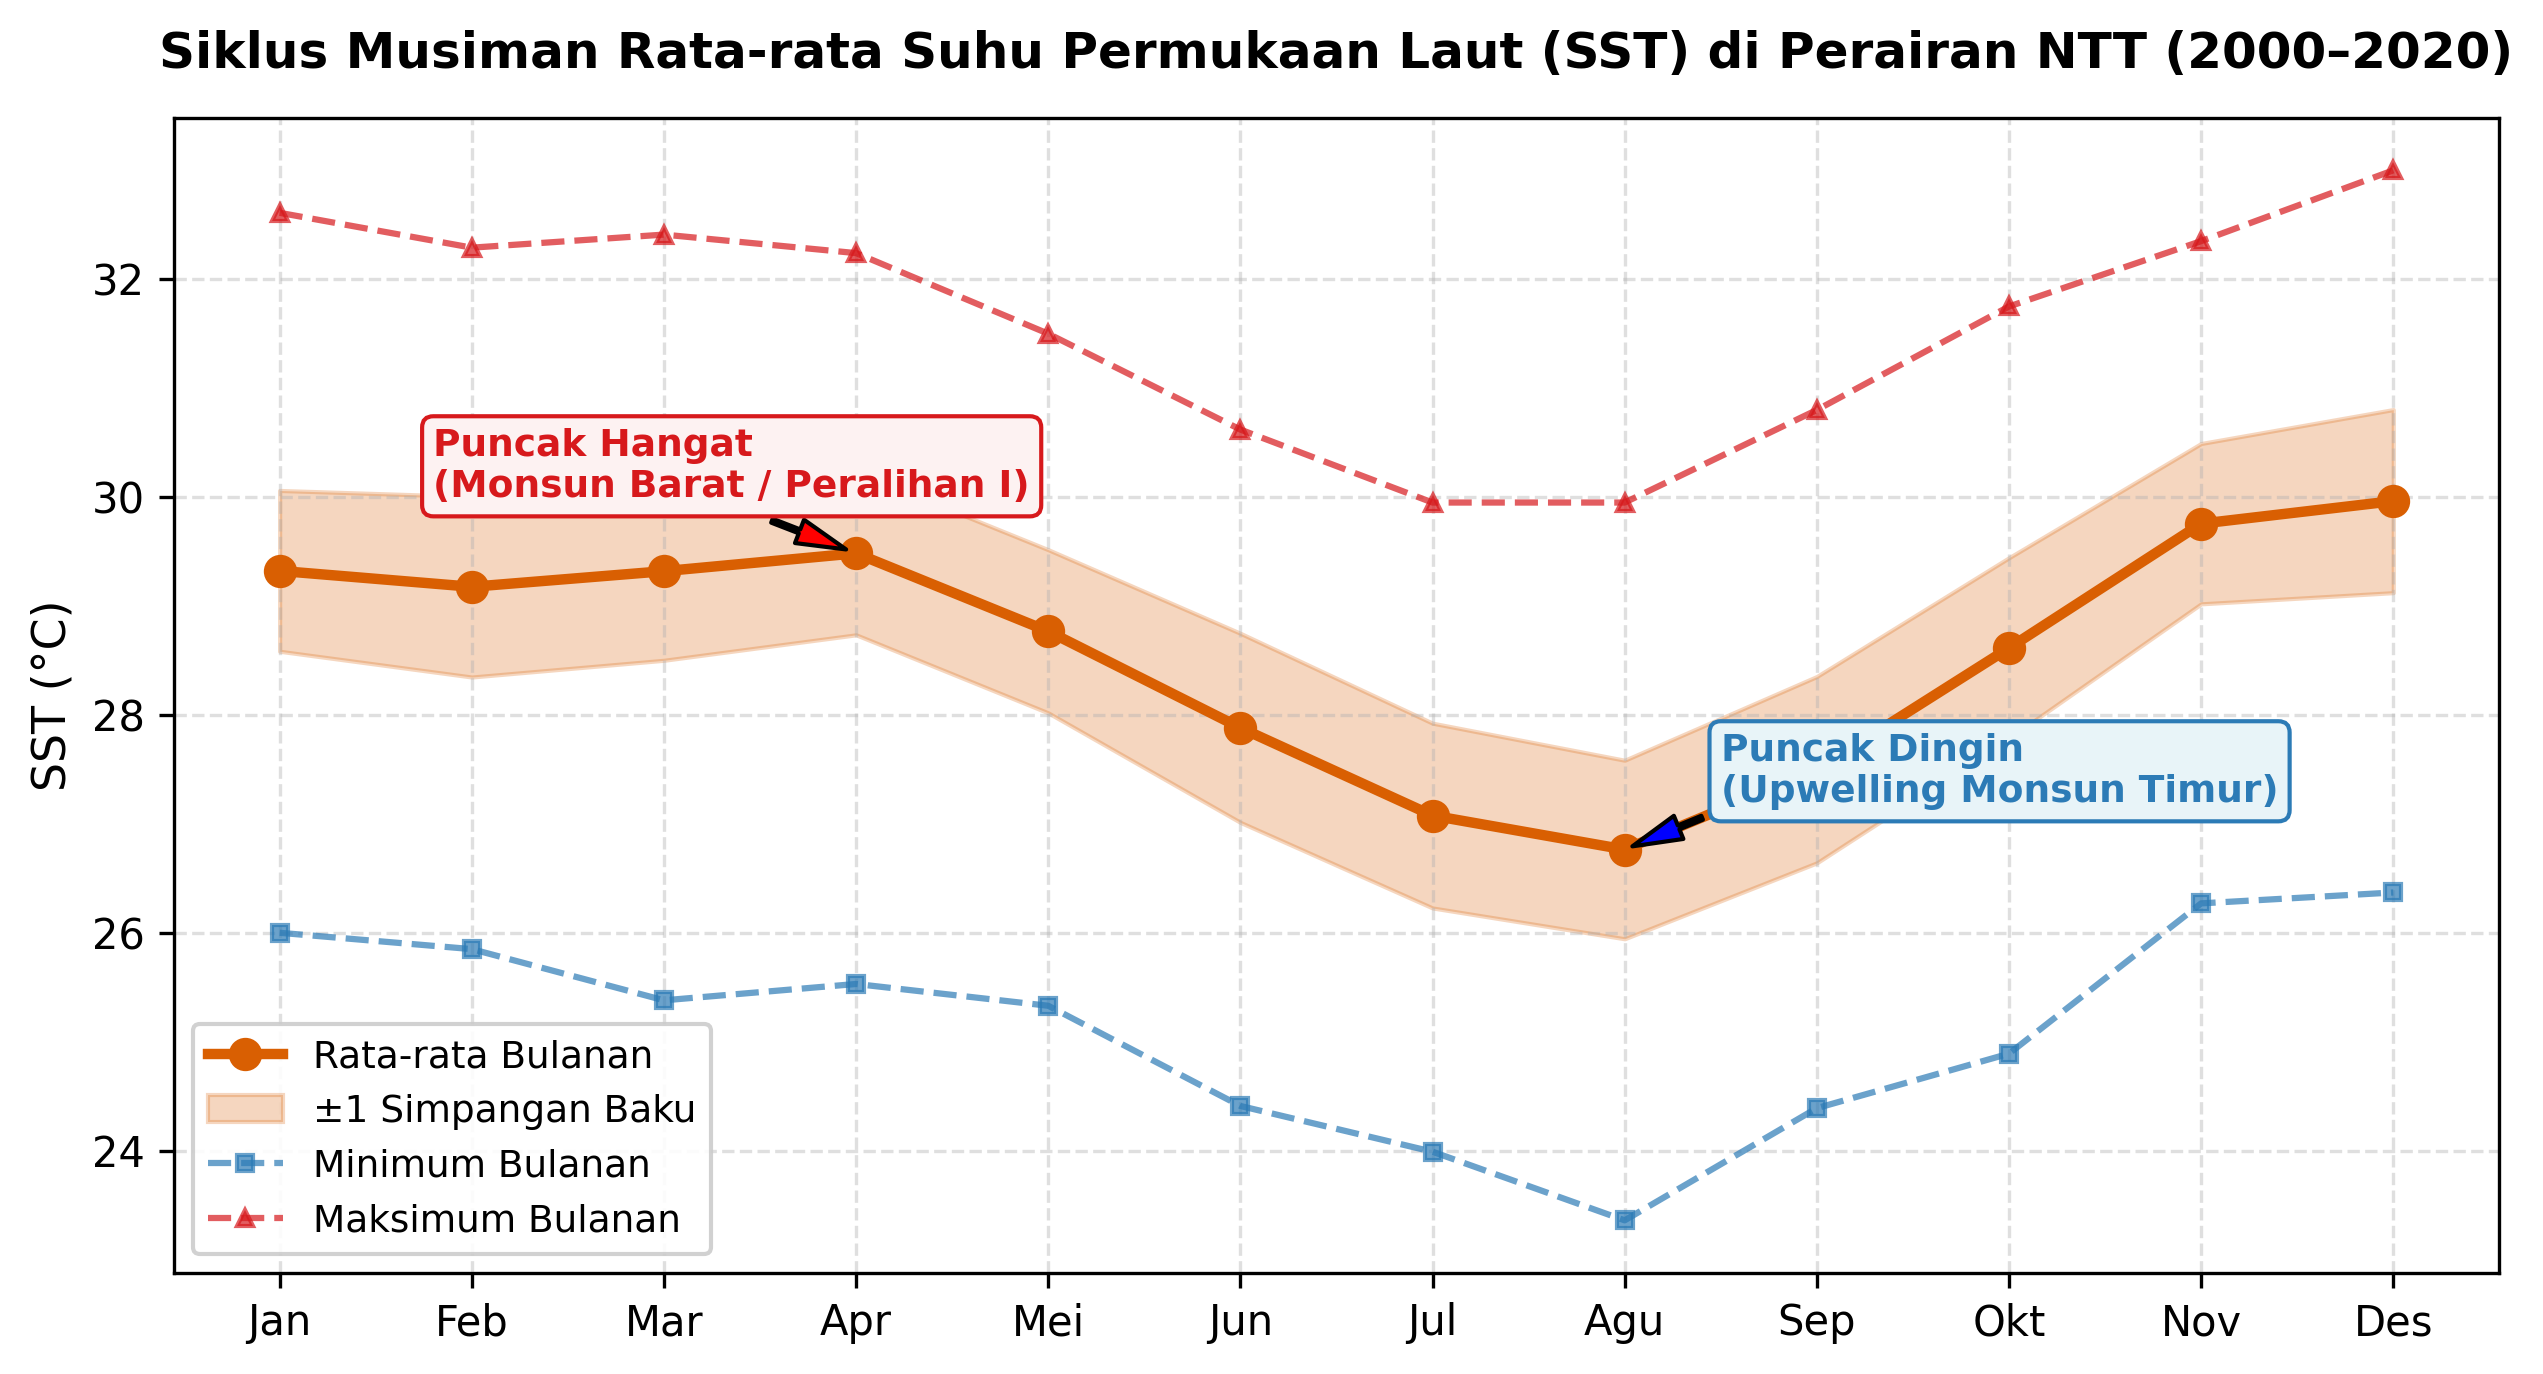

✅ Gambar siklus musiman SST disimpan.


In [6]:
# ==============================================================================
# 7. ANALISIS TEMPORAL SST
# ==============================================================================
monthly_sst = sst.groupby('time.month').mean(dim=['time', 'lat', 'lon'])
monthly_std = sst.groupby('time.month').std(dim=['time', 'lat', 'lon'])
monthly_min = sst.groupby('time.month').min(dim=['time', 'lat', 'lon'])
monthly_max = sst.groupby('time.month').max(dim=['time', 'lat', 'lon'])

months = np.arange(1, 13)
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun', 'Jul', 'Agu', 'Sep', 'Okt', 'Nov', 'Des']

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(months, monthly_sst.values, 'o-', color='#d95f02', linewidth=2.5, markersize=7, label='Rata-rata Bulanan')
ax.fill_between(months, monthly_sst.values - monthly_std.values, monthly_sst.values + monthly_std.values,
                alpha=0.25, color='#d95f02', label='±1 Simpangan Baku')
ax.plot(months, monthly_min.values, 's--', color='#2c7bb6', alpha=0.7, markersize=4, label='Minimum Bulanan')
ax.plot(months, monthly_max.values, '^--', color='#d7191c', alpha=0.7, markersize=4, label='Maksimum Bulanan')

ax.set_xticks(months)
ax.set_xticklabels(month_names, fontsize=10)
ax.set_ylabel('SST (°C)', fontsize=11)
ax.set_title('Siklus Musiman Rata-rata Suhu Permukaan Laut (SST) di Perairan NTT (2000–2020)', fontsize=12, fontweight='bold', pad=12)
ax.grid(True, linestyle='--', alpha=0.4)
ax.legend(loc='lower left', framealpha=0.9, fontsize=9)

# Anotasi fenomena monsun
ax.annotate('Puncak Dingin\n(Upwelling Monsun Timur)', xy=(8, monthly_sst.values[7]), xytext=(8.5, 27.2),
            arrowprops=dict(facecolor='blue', shrink=0.08, width=1, headwidth=6),
            fontsize=9, fontweight='semibold', color='#2c7bb6', bbox=dict(boxstyle="round,pad=0.3", fc="#e8f4f8", ec="#2c7bb6", lw=1))
ax.annotate('Puncak Hangat\n(Monsun Barat / Peralihan I)', xy=(4, monthly_sst.values[3]), xytext=(1.8, 30.0),
            arrowprops=dict(facecolor='red', shrink=0.08, width=1, headwidth=6),
            fontsize=9, fontweight='semibold', color='#d7191c', bbox=dict(boxstyle="round,pad=0.3", fc="#fdf2f2", ec="#d7191c", lw=1))

fig.savefig(cfg.FIGURES_DIR / "nb2_sst_seasonal_cycle.png", dpi=cfg.FIGURE_DPI, bbox_inches='tight')
plt.show()
print("✅ Gambar siklus musiman SST disimpan.")


### 8. Analisis Spasial SST: Pola Musiman 4 Panel
Visualisasi rata-rata spasial SST pada 4 musim utama:
- **DJF**: Monsun Barat (Desember, Januari, Februari)
- **MAM**: Masa Peralihan I (Maret, April, Mei)
- **JJA**: Monsun Timur / Puncak Upwelling (Juni, Juli, Agustus)
- **SON**: Masa Peralihan II (September, Oktober, November)


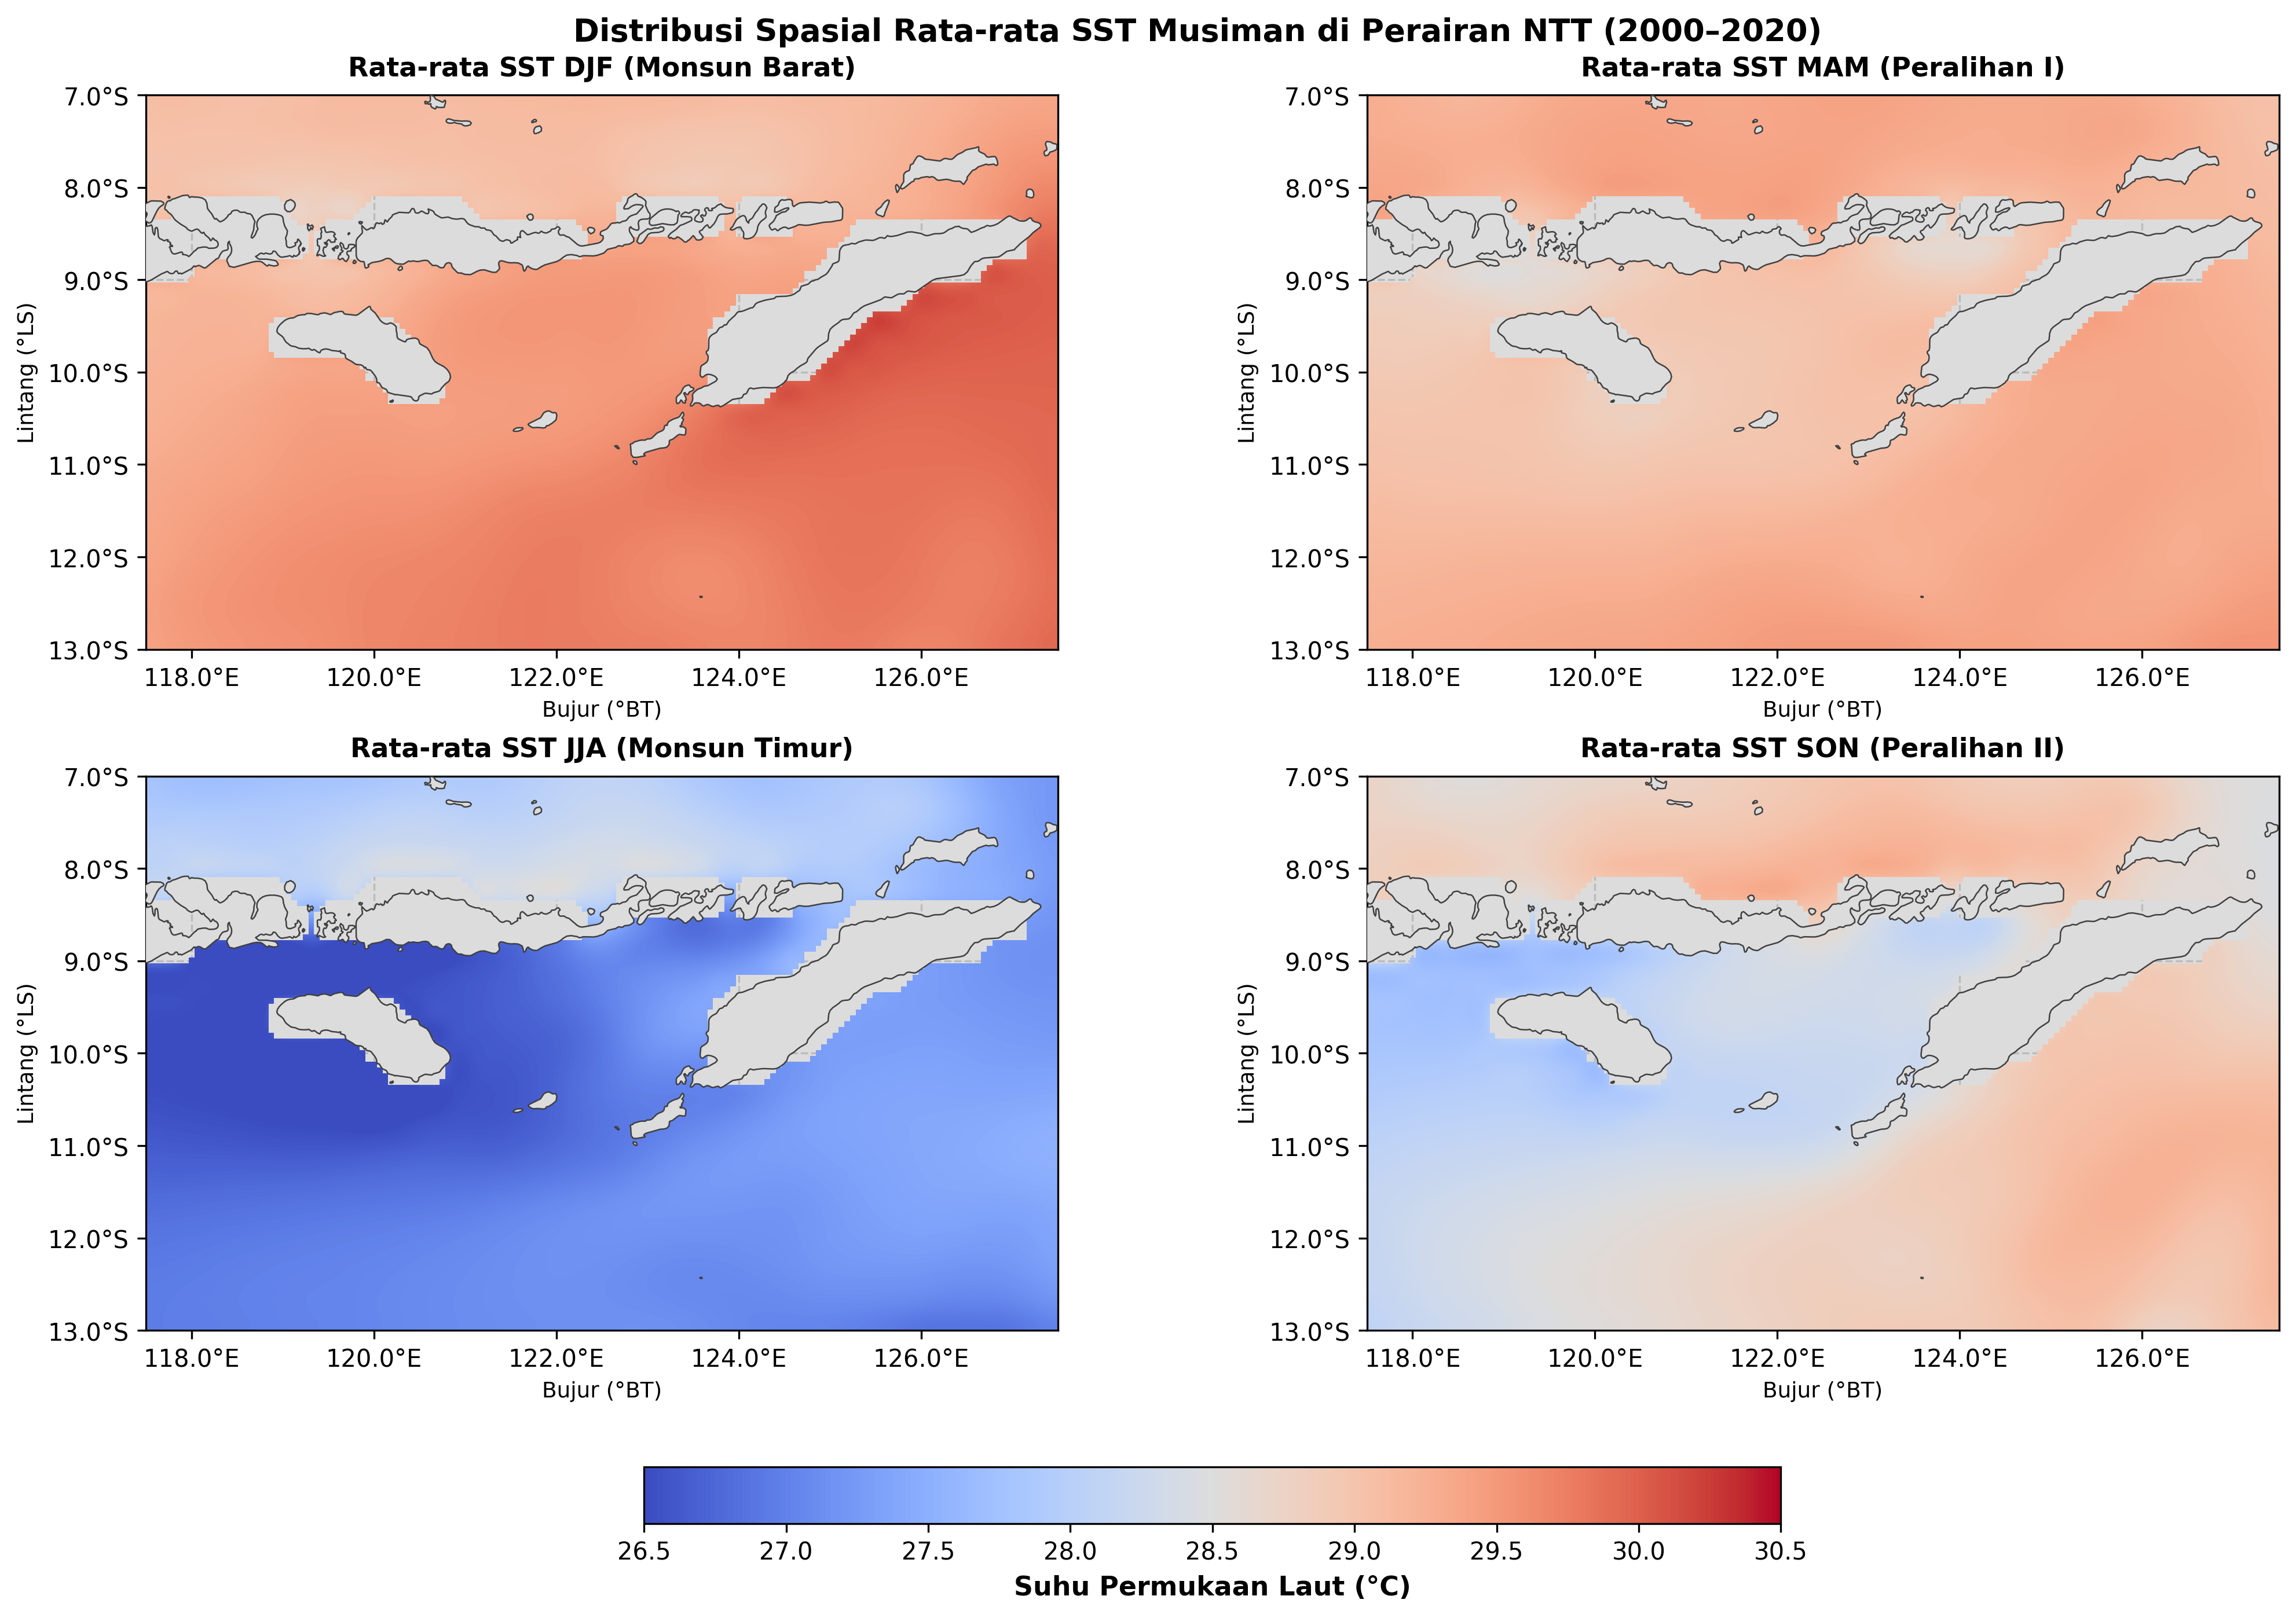

✅ Peta spasial musiman SST disimpan.


In [7]:
# ==============================================================================
# 8. ANALISIS SPASIAL SST MUSIMAN
# ==============================================================================
seasons = {
    'DJF (Monsun Barat)': [12, 1, 2],
    'MAM (Peralihan I)': [3, 4, 5],
    'JJA (Monsun Timur)': [6, 7, 8],
    'SON (Peralihan II)': [9, 10, 11]
}

seasonal_sst = {}
for s_name, m_list in seasons.items():
    seasonal_sst[s_name] = sst.sel(time=sst.time.dt.month.isin(m_list)).mean(dim='time').values

fig, axes = plt.subplots(2, 2, figsize=(14, 9), constrained_layout=True)
axes_flat = axes.flatten()
im_last = None

for idx, (s_name, s_data) in enumerate(seasonal_sst.items()):
    ax = axes_flat[idx]
    im_last = plot_smooth_map(ax, longitudes, latitudes, s_data, cmap='coolwarm', vmin=26.5, vmax=30.5)
    ax.set_title(f"Rata-rata SST {s_name}", fontsize=11, fontweight='bold', pad=8)

cbar = fig.colorbar(im_last, ax=axes, orientation='horizontal', fraction=0.046, pad=0.05, shrink=0.6)
cbar.set_label('Suhu Permukaan Laut (°C)', fontsize=11, fontweight='semibold')
fig.suptitle('Distribusi Spasial Rata-rata SST Musiman di Perairan NTT (2000–2020)', fontsize=13, fontweight='bold', y=1.02)

fig.savefig(cfg.FIGURES_DIR / "nb2_sst_spatial_patterns.png", dpi=cfg.FIGURE_DPI, bbox_inches='tight')
plt.show()
print("✅ Peta spasial musiman SST disimpan.")


### 9. Perhitungan Klimatologi dan Ambang Batas P90 Per Grid (Jendela 11 Hari, Smoothing 31 Hari)
Menerapkan `calculate_daily_climatology` secara independen untuk setiap grid koordinat latitude-longitude.


Menghitung klimatologi (jendela 11 hari) dan ambang P90 (smoothing 31 hari) per grid...


C:\Users\Yusufalqodri\AppData\Local\Temp\ipykernel_42124\1129045113.py:11: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  doy = dates.dayofyear.to_numpy().astype(int)


Perhitungan selesai dalam 43.3 detik.


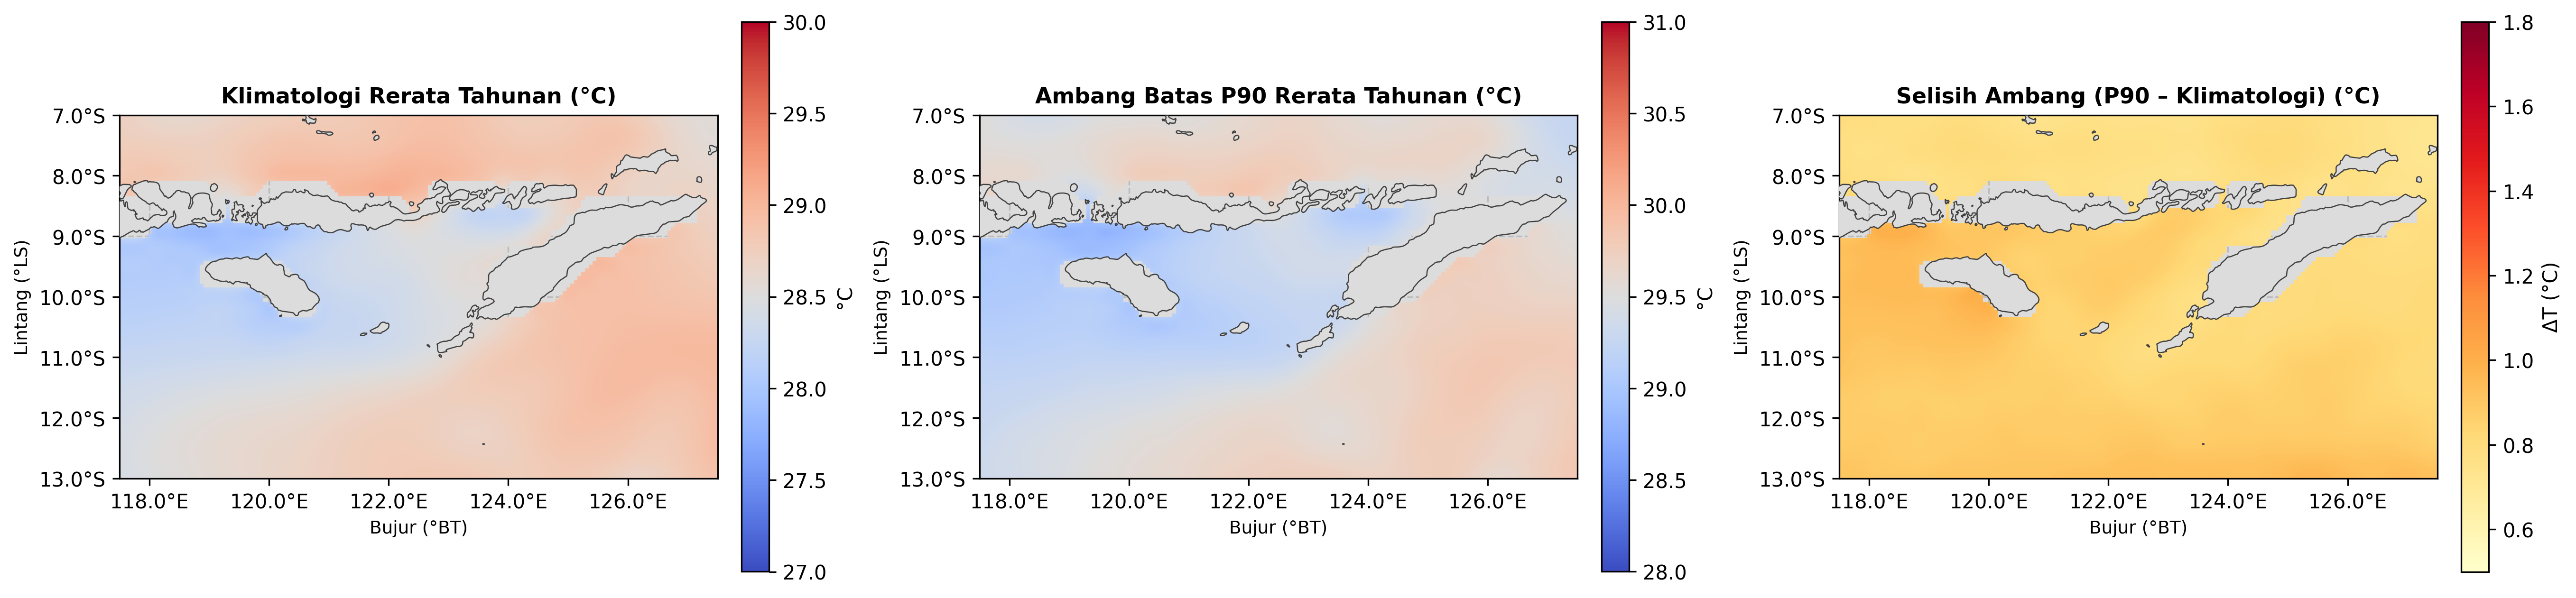

In [8]:
# ==============================================================================
# 9. PERHITUNGAN KLIMATOLOGI DAN THRESHOLD PER GRID
# ==============================================================================
day_idx = calendar_day_index(dates)

clim_all = np.full((nt, nlat, nlon), np.nan, dtype=np.float32)
thresh_all = np.full((nt, nlat, nlon), np.nan, dtype=np.float32)
clim_doy_all = np.full((366, nlat, nlon), np.nan, dtype=np.float32)
thresh_doy_all = np.full((366, nlat, nlon), np.nan, dtype=np.float32)

t_start = time.time()
print("Menghitung klimatologi (jendela 11 hari) dan ambang P90 (smoothing 31 hari) per grid...")

for iy in range(nlat):
    for ix in range(nlon):
        series = sst_values[:, iy, ix]
        if np.count_nonzero(np.isfinite(series)) < 5:
            continue
        
        c366, p366 = calculate_daily_climatology(
            series, day_idx, percentile=cfg.MHW_PERCENTILE,
            clim_window=11, smooth_window=31
        )
        clim_doy_all[:, iy, ix] = c366
        thresh_doy_all[:, iy, ix] = p366
        clim_all[:, iy, ix] = c366[day_idx - 1]
        thresh_all[:, iy, ix] = p366[day_idx - 1]

print(f"Perhitungan selesai dalam {time.time() - t_start:.1f} detik.")

# Visualisasi Klimatologi, P90, dan Selisih (Ambang Anomali)
fig, axes = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)

clim_mean_map = np.nanmean(clim_doy_all, axis=0)
thresh_mean_map = np.nanmean(thresh_doy_all, axis=0)
diff_map = thresh_mean_map - clim_mean_map

im0 = plot_smooth_map(axes[0], longitudes, latitudes, clim_mean_map, cmap='coolwarm', vmin=27.0, vmax=30.0)
axes[0].set_title("Klimatologi Rerata Tahunan (°C)", fontsize=11, fontweight='bold')
fig.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04, label="°C")

im1 = plot_smooth_map(axes[1], longitudes, latitudes, thresh_mean_map, cmap='coolwarm', vmin=28.0, vmax=31.0)
axes[1].set_title("Ambang Batas P90 Rerata Tahunan (°C)", fontsize=11, fontweight='bold')
fig.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04, label="°C")

im2 = plot_smooth_map(axes[2], longitudes, latitudes, diff_map, cmap='YlOrRd', vmin=0.5, vmax=1.8)
axes[2].set_title("Selisih Ambang (P90 – Klimatologi) (°C)", fontsize=11, fontweight='bold')
fig.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04, label="ΔT (°C)")

fig.savefig(cfg.FIGURES_DIR / "nb2_sst_climatology_threshold.png", dpi=cfg.FIGURE_DPI, bbox_inches='tight')
plt.show()


### 10. Deteksi MHW Independen Per Grid (Filter Sebelum Penggabungan & Syarat Celah)
Mendeteksi seluruh kejadian MHW lokal pada setiap grid secara independen.


Deteksi per grid selesai dalam 5.4 detik.
Total kejadian MHW lokal di seluruh grid: 37174

Distribusi Kategori MHW Lokal:
 - Moderate  :  27795 kejadian ( 74.8%)
 - Strong    :   8966 kejadian ( 24.1%)
 - Severe    :    393 kejadian (  1.1%)
 - Extreme   :     20 kejadian (  0.1%)


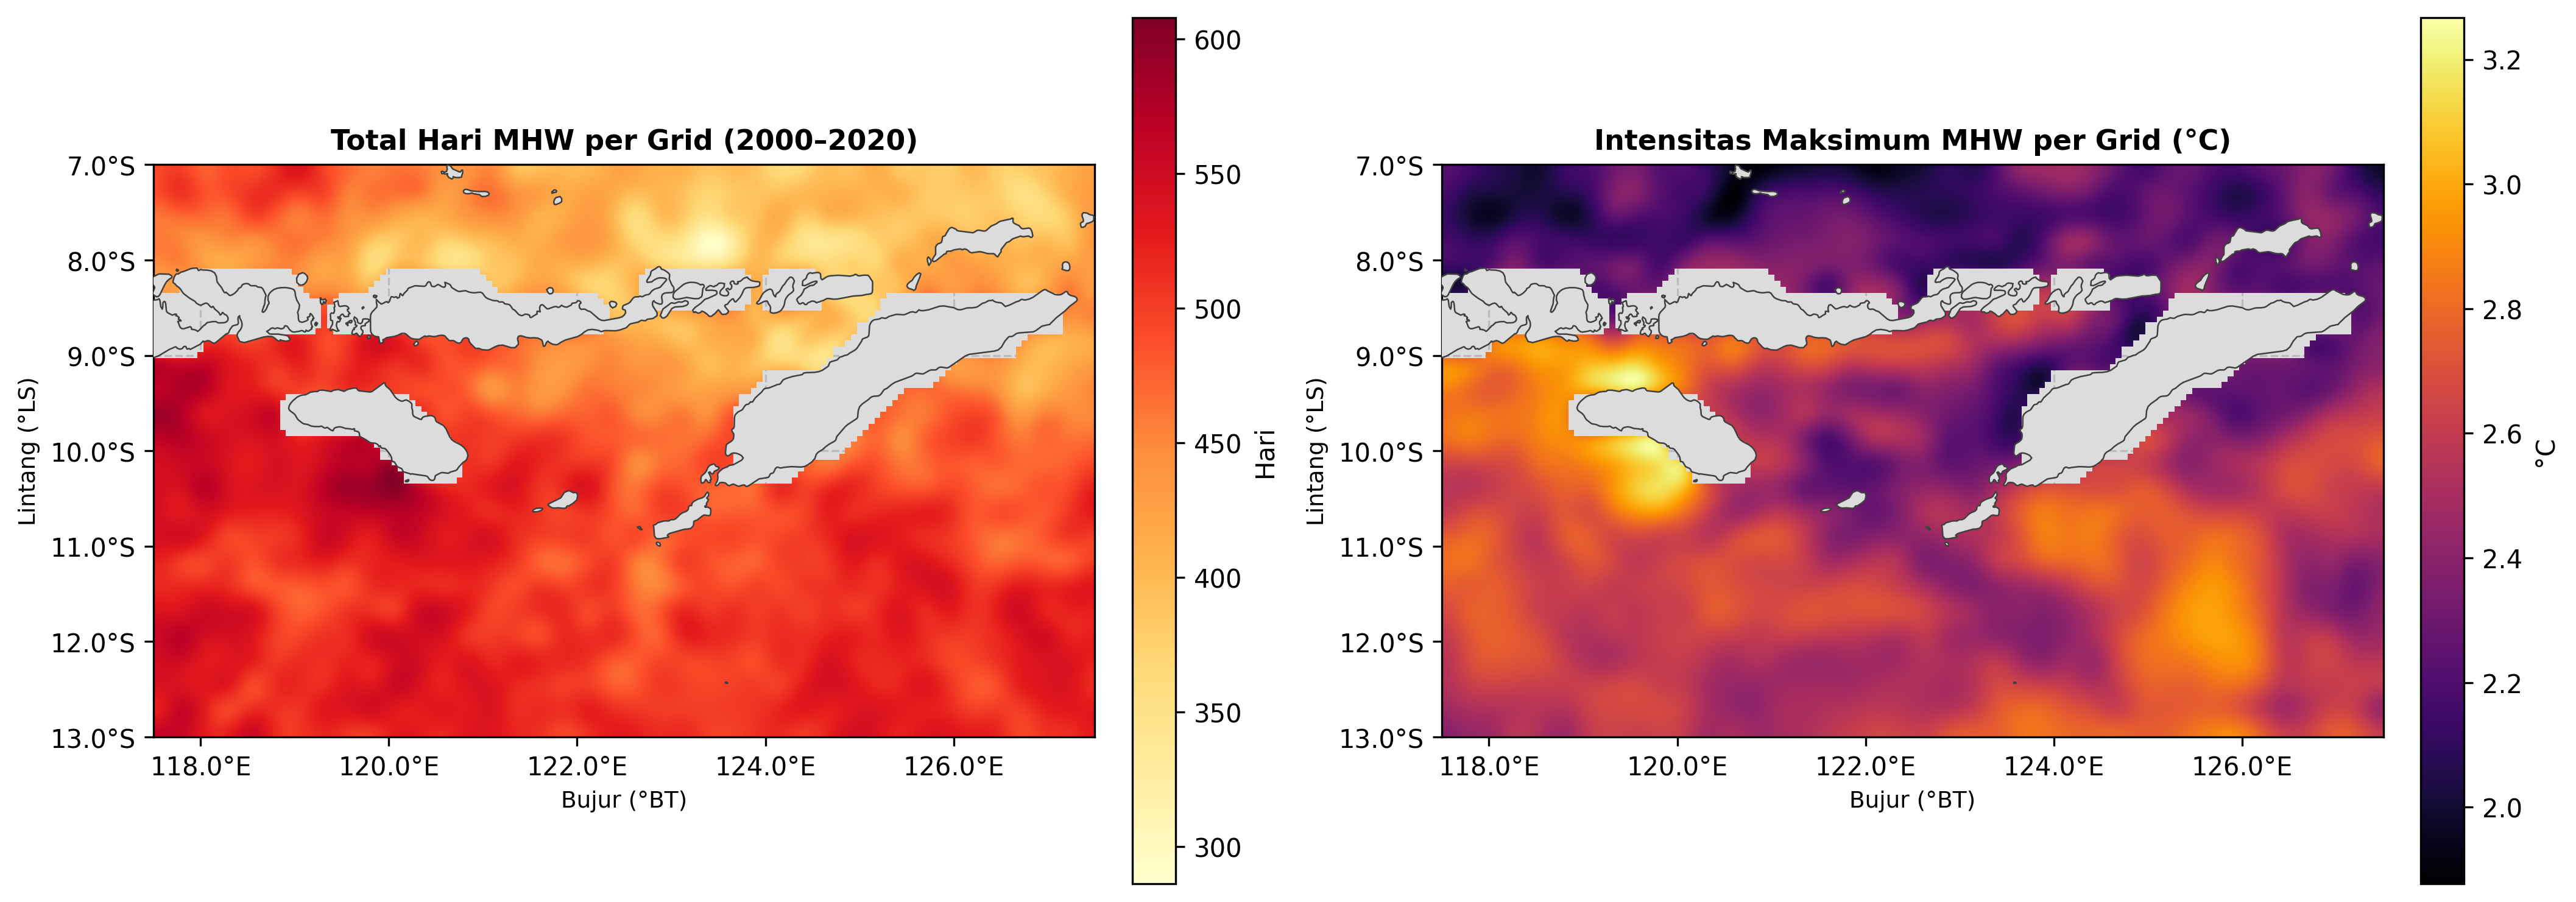

In [9]:
# ==============================================================================
# 10. DETEKSI MHW INDEPENDEN PER GRID
# ==============================================================================
mhw_mask_all = np.zeros((nt, nlat, nlon), dtype=np.int8)
strict_mask_all = np.zeros((nt, nlat, nlon), dtype=np.int8)
category_all = np.zeros((nt, nlat, nlon), dtype=np.uint8)

all_local_events = []
t_start = time.time()

for iy in range(nlat):
    for ix in range(nlon):
        series = sst_values[:, iy, ix]
        if np.count_nonzero(np.isfinite(series)) < 5:
            continue
            
        c_series = clim_all[:, iy, ix]
        t_series = thresh_all[:, iy, ix]
        
        events, labels = detect_events_one_grid(
            series, c_series, t_series, dates,
            min_duration=cfg.MHW_MIN_DURATION_DAYS, max_gap=2, filter_before_merge=True
        )
        
        in_ev = labels > 0
        mhw_mask_all[in_ev, iy, ix] = 1
        strict_mask_all[in_ev & (series > t_series), iy, ix] = 1
        
        # Hitung rasio intensitas untuk kategori harian
        denom = t_series - c_series
        diff = series - c_series
        ratio = np.divide(diff, denom, out=np.full_like(diff, np.nan), where=np.isfinite(denom) & (denom > 0))
        category_all[in_ev & (ratio < 2), iy, ix] = 1
        category_all[in_ev & (ratio >= 2) & (ratio < 3), iy, ix] = 2
        category_all[in_ev & (ratio >= 3) & (ratio < 4), iy, ix] = 3
        category_all[in_ev & (ratio >= 4), iy, ix] = 4
        
        for ev in events:
            ev["lat"] = float(latitudes[iy])
            ev["lon"] = float(longitudes[ix])
            all_local_events.append(ev)

df_local_events = pd.DataFrame(all_local_events)
print(f"Deteksi per grid selesai dalam {time.time() - t_start:.1f} detik.")
print(f"Total kejadian MHW lokal di seluruh grid: {len(df_local_events)}")

# Distribusi Kategori Lokal
cat_counts = df_local_events['category'].value_counts()
print("\nDistribusi Kategori MHW Lokal:")
for cat_name, count in cat_counts.items():
    print(f" - {cat_name:10s}: {count:6d} kejadian ({count/len(df_local_events)*100:5.1f}%)")

# Peta spasial total hari MHW dan intensitas maksimum lokal
total_mhw_days_grid = np.sum(mhw_mask_all, axis=0).astype(float)
total_mhw_days_grid[ocean_mask == 0] = np.nan

intensity_all = sst_values - clim_all
intensity_all[mhw_mask_all == 0] = np.nan
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=RuntimeWarning)
    max_intensity_grid = np.nanmax(intensity_all, axis=0)
max_intensity_grid[ocean_mask == 0] = np.nan

fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
im0 = plot_smooth_map(axes[0], longitudes, latitudes, total_mhw_days_grid, cmap='YlOrRd')
axes[0].set_title("Total Hari MHW per Grid (2000–2020)", fontsize=11, fontweight='bold')
fig.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04, label="Hari")

im1 = plot_smooth_map(axes[1], longitudes, latitudes, max_intensity_grid, cmap='inferno')
axes[1].set_title("Intensitas Maksimum MHW per Grid (°C)", fontsize=11, fontweight='bold')
fig.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04, label="°C")

fig.savefig(cfg.FIGURES_DIR / "nb2_mhw_spatial_maps.png", dpi=cfg.FIGURE_DPI, bbox_inches='tight')
plt.show()


### 11. Pembentukan Katalog Kejadian MHW Regional (Ambang Cakupan $\ge 15\%$)
Menghitung persentase cakupan harian grid MHW aktif terhadap seluruh grid laut valid dan mengelompokkannya menjadi kejadian regional.


Jumlah kejadian MHW regional terdeteksi: 45
Total hari MHW regional (cakupan >=15%): 864 hari


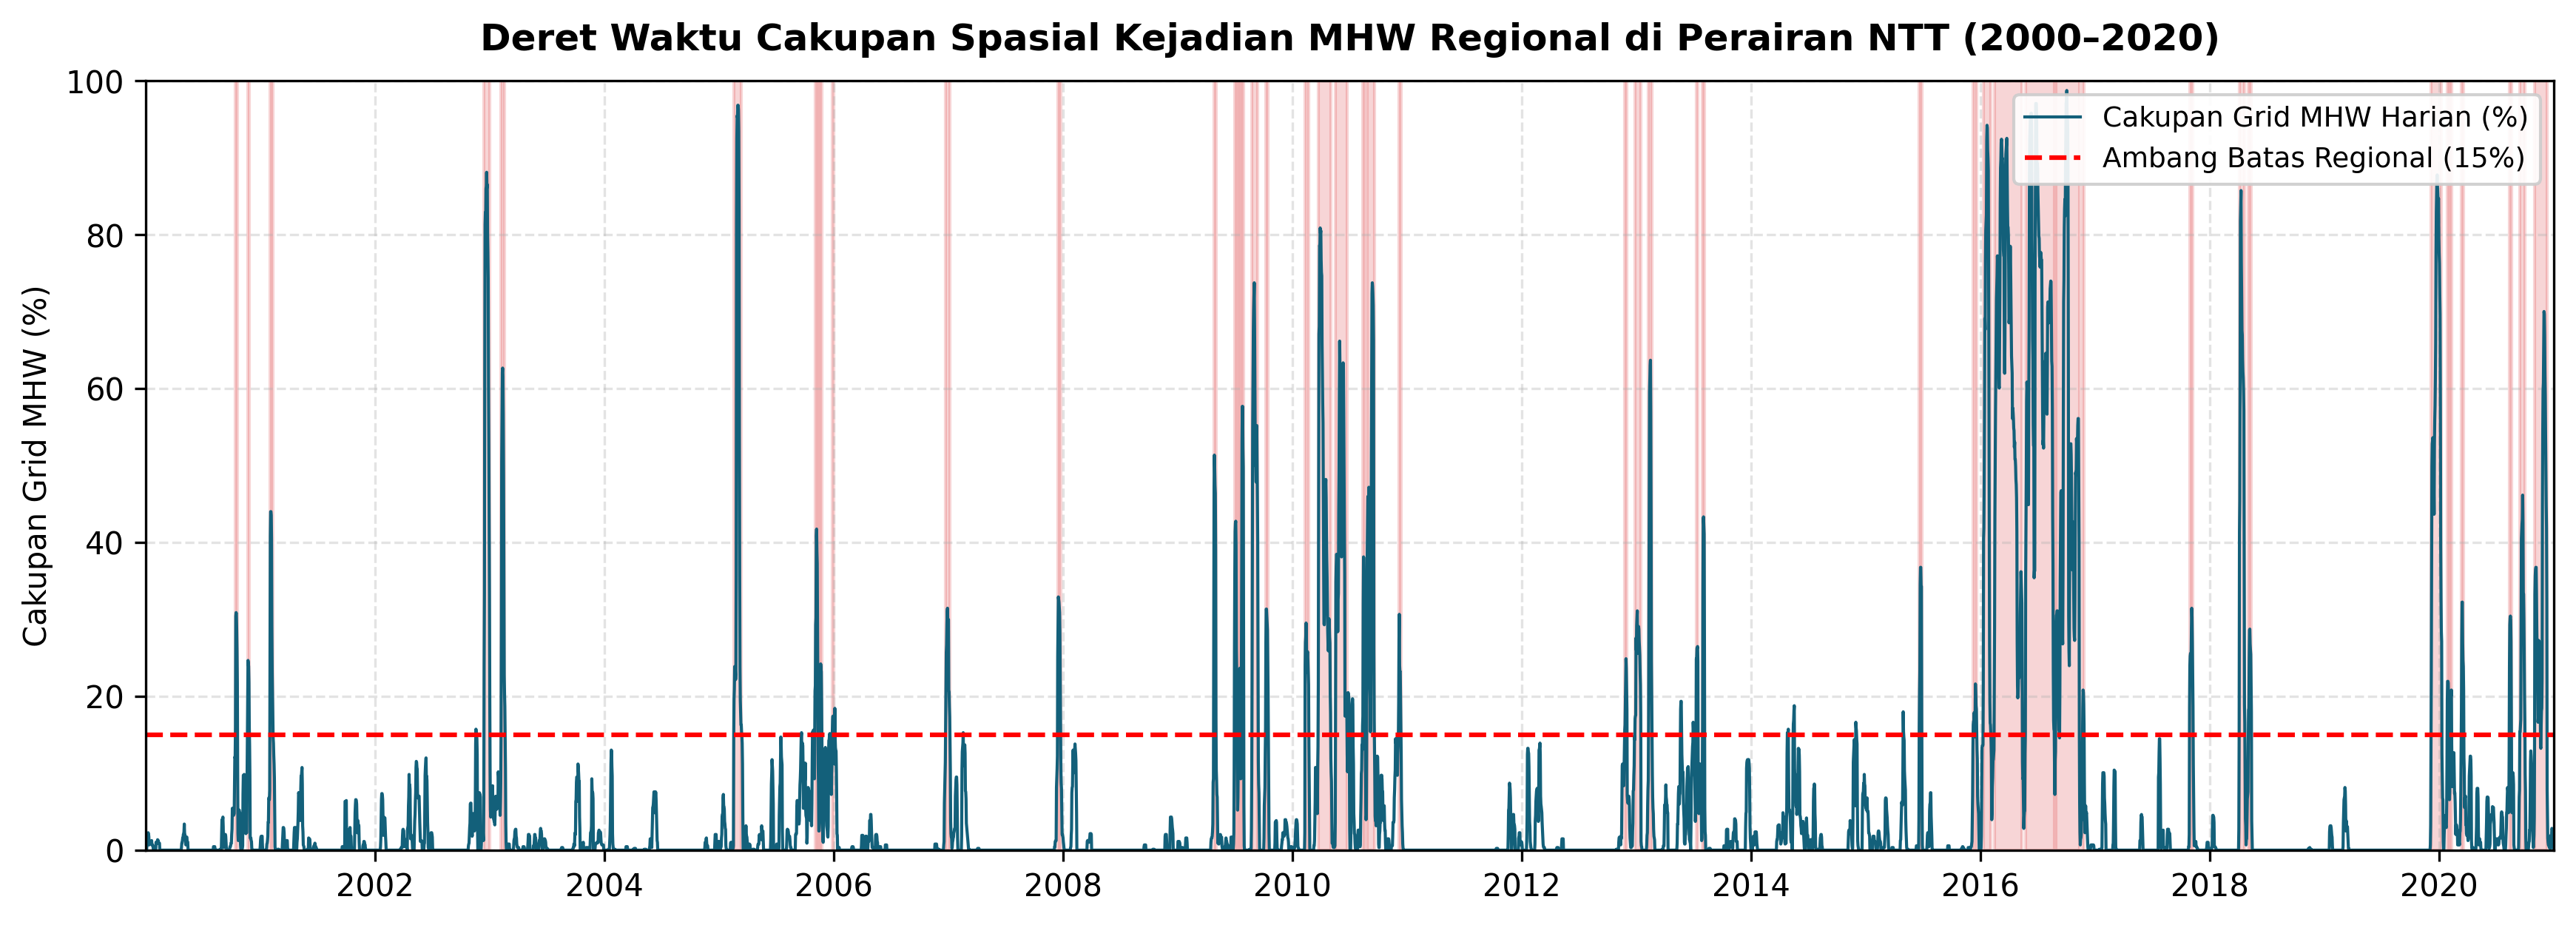

In [10]:
# ==============================================================================
# 11. PEMBENTUKAN KATALOG MHW REGIONAL
# ==============================================================================
daily_valid_grid = np.isfinite(sst_values) & np.isfinite(clim_all) & np.isfinite(thresh_all)
available_grid_daily = np.sum(daily_valid_grid, axis=(1, 2))
active_grid_daily = np.sum((mhw_mask_all == 1) & daily_valid_grid, axis=(1, 2))
strict_grid_daily = np.sum((strict_mask_all == 1) & daily_valid_grid, axis=(1, 2))

member_extent = np.divide(active_grid_daily, available_grid_daily, out=np.zeros(nt, dtype=np.float32), where=available_grid_daily > 0)
strict_extent = np.divide(strict_grid_daily, available_grid_daily, out=np.zeros(nt, dtype=np.float32), where=available_grid_daily > 0)
mhw_percentage = member_extent * 100.0

df_regional_events = build_regional_events(
    mhw_percentage, dates, threshold=15.0, min_duration=5, max_gap=2, filter_before_merge=True
)

print(f"Jumlah kejadian MHW regional terdeteksi: {len(df_regional_events)}")
print(f"Total hari MHW regional (cakupan >=15%): {int(np.sum(mhw_percentage >= 15.0))} hari")

# Visualisasi Timeline Cakupan Spasial Regional Harian
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(dates, mhw_percentage, color='#13607A', linewidth=1.0, label='Cakupan Grid MHW Harian (%)')
ax.axhline(15.0, color='red', linestyle='--', linewidth=1.5, label='Ambang Batas Regional (15%)')

# Tandai blok kejadian regional
for _, ev in df_regional_events.iterrows():
    ax.axvspan(ev['start_date'], ev['end_date'], color='#d7191c', alpha=0.18)

ax.set_xlim(dates.min(), dates.max())
ax.set_ylim(0, 100)
ax.set_ylabel('Cakupan Grid MHW (%)', fontsize=10)
ax.set_title('Deret Waktu Cakupan Spasial Kejadian MHW Regional di Perairan NTT (2000–2020)', fontsize=12, fontweight='bold', pad=10)
ax.grid(True, linestyle='--', alpha=0.35)
ax.legend(loc='upper right', framealpha=0.9, fontsize=9)

fig.savefig(cfg.FIGURES_DIR / "nb2_mhw_timeline.png", dpi=cfg.FIGURE_DPI, bbox_inches='tight')
fig.savefig(cfg.FIGURES_DIR / "nb2_mhw_daily_extent_check.png", dpi=cfg.FIGURE_DPI, bbox_inches='tight')
plt.show()


### 12. Perhitungan Intensitas Maksimum per Grid untuk Setiap Kejadian Regional
Untuk setiap kejadian regional $e$:
$$I_{max,e}(i,j) = \max_{t \in \text{active}} [SST(t) - \text{Clim}(t)]$$
Grid yang tidak aktif MHW diberi nilai NaN.


In [11]:
# ==============================================================================
# 12. ANALISIS INTENSITAS MAKSIMUM PER GRID SETIAP KEJADIAN REGIONAL
# ==============================================================================
grid_intensity_by_event = {}
regional_records = []
all_grid_records = []

for _, ev in df_regional_events.iterrows():
    eid = int(ev["regional_event_id"])
    s_date, e_date = ev["start_date"], ev["end_date"]
    t_mask = (dates >= np.datetime64(s_date)) & (dates <= np.datetime64(e_date))
    t_indices = np.where(t_mask)[0]
    
    # Tanggal puncak cakupan
    ev_extents = mhw_percentage[t_indices]
    peak_offset = int(np.argmax(ev_extents))
    peak_date = dates[t_indices[peak_offset]]
    
    sst_p = sst_values[t_indices]
    clim_p = clim_all[t_indices]
    mhw_p = mhw_mask_all[t_indices]
    int_p = sst_p - clim_p
    
    valid_mhw = (mhw_p == 1) & np.isfinite(int_p)
    int_mhw = np.where(valid_mhw, int_p, np.nan)
    
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)
        grid_max = np.nanmax(int_mhw, axis=0)
    grid_max[~np.any(valid_mhw, axis=0)] = np.nan
    grid_intensity_by_event[eid] = grid_max
    
    val = grid_max[np.isfinite(grid_max)]
    num_grids = len(val)
    if num_grids > 0:
        mean_int = float(np.mean(val))
        max_int = float(np.max(val))
        min_int = float(np.min(val))
        std_int = float(np.std(val, ddof=0))
        iy, ix = np.unravel_index(np.nanargmax(grid_max), grid_max.shape)
        max_lat, max_lon = float(latitudes[iy]), float(longitudes[ix])
        cum_int = float(np.nansum(np.where(valid_mhw, int_p, 0.0))) / float(num_grids)
    else:
        mean_int, max_int, min_int, std_int = np.nan, np.nan, np.nan, np.nan
        max_lat, max_lon, cum_int = np.nan, np.nan, np.nan
        
    cat_ev = category_all[t_indices]
    max_cat_num = int(np.max(cat_ev)) if np.any(cat_ev > 0) else 1
    cat_map = {1: "Moderate", 2: "Strong", 3: "Severe", 4: "Extreme"}
    ev_cat = cat_map.get(max_cat_num, "Moderate")
        
    for iy in range(nlat):
        for ix in range(nlon):
            if np.isfinite(grid_max[iy, ix]):
                all_grid_records.append({
                    "event_id": eid,
                    "regional_event_id": eid,
                    "start_date": s_date.strftime("%Y-%m-%d"),
                    "end_date": e_date.strftime("%Y-%m-%d"),
                    "duration_days": int(ev["duration_days"]),
                    "latitude": float(latitudes[iy]),
                    "longitude": float(longitudes[ix]),
                    "intensitas_maksimum_C": round(float(grid_max[iy, ix]), 3),
                    "intensitas_maksimum_rata_rata_regional_C": round(mean_int, 3)
                })
                
    regional_records.append({
        "regional_event_id": eid,
        "event_id": eid,
        "start_idx": int(t_indices[0]),
        "end_idx": int(t_indices[-1]),
        "start_date": s_date.strftime("%Y-%m-%d"),
        "end_date": e_date.strftime("%Y-%m-%d"),
        "peak_date": peak_date.strftime("%Y-%m-%d"),
        "duration_days": int(ev["duration_days"]),
        "hari_mhw_regional": int(ev["hari_mhw_regional"]),
        "hari_jeda": int(ev["hari_jeda"]),
        "mean_grid_percentage": ev["mean_grid_percentage"],
        "max_grid_percentage": ev["max_grid_percentage"],
        "mean_extent_pct": ev["mean_extent_pct"],
        "peak_extent_pct": ev["peak_extent_pct"],
        "jumlah_grid_mengalami_mhw": num_grids,
        "intensitas_maksimum_regional_C": round(max_int, 3),
        "i_max_regional": round(max_int, 3),
        "i_max": round(max_int, 3),
        "intensitas_maksimum_rata_rata_regional_C": round(mean_int, 3),
        "i_mean_regional": round(mean_int, 3),
        "i_mean": round(mean_int, 3),
        "cum_intensity_regional": round(cum_int, 2),
        "i_cum": round(cum_int, 2),
        "category": ev_cat,
        "intensitas_minimum_maksimum_grid_C": round(min_int, 3),
        "standar_deviasi_intensitas_grid_C": round(std_int, 3),
        "latitude_grid_maksimum": max_lat,
        "longitude_grid_maksimum": max_lon
    })

df_catalog = pd.DataFrame(regional_records)
df_grid_max_intensity = pd.DataFrame(all_grid_records)

print(f"✅ Analisis intensitas maksimum per grid selesai untuk {len(df_catalog)} kejadian regional.")
print(f"Total baris data intensitas per grid: {len(df_grid_max_intensity)}")


✅ Analisis intensitas maksimum per grid selesai untuk 45 kejadian regional.
Total baris data intensitas per grid: 21204


### 13. Pemeringkatan Top 3 Kejadian MHW Regional Berdasarkan Intensitas Maksimum
Sesuai metodologi yang telah diklarifikasi:
$$I_{max,regional}(e) = \max_{i,j}[I_{max,e}(i,j)]$$
Pemeringkatan diurutkan berdasarkan nilai anomali maksimum tertinggi dari seluruh grid laut yang mengalami MHW pada kejadian tersebut.


In [12]:
# ==============================================================================
# 13. PEMERINGKATAN TOP 3 KEJADIAN REGIONAL
# ==============================================================================
df_ranked = df_catalog.sort_values("intensitas_maksimum_regional_C", ascending=False).reset_index(drop=True)
df_ranked["peringkat_regional"] = np.arange(1, len(df_ranked) + 1)
df_top3 = df_ranked.head(3).copy()

print("=" * 80)
print("TOP 3 KEJADIAN MHW REGIONAL DI PERAIRAN NTT (2000–2020)")
print("Berdasarkan Intensitas Maksimum Regional: I_max,regional(e) = max[I_max,e(i,j)]")
print("=" * 80)
for _, r in df_top3.iterrows():
    print(f"Peringkat {int(r['peringkat_regional'])}: Event #{int(r['event_id'])}")
    print(f"  Periode             : {r['start_date']} s.d. {r['end_date']} (Puncak: {r['peak_date']})")
    print(f"  Durasi              : {r['duration_days']} hari (Hari Aktif Regional: {r['hari_mhw_regional']} hari)")
    print(f"  Cakupan Spasial     : Rata-rata {r['mean_extent_pct']}%, Puncak {r['peak_extent_pct']}%")
    print(f"  Intensitas Maksimum : {r['intensitas_maksimum_regional_C']} °C (Lokasi: {r['latitude_grid_maksimum']}°S, {r['longitude_grid_maksimum']}°E)")
    print(f"  Intensitas Rata-rata: {r['intensitas_maksimum_rata_rata_regional_C']} °C")
    print("-" * 80)

# Tampilkan DataFrame Top 3
display(df_top3[['peringkat_regional', 'event_id', 'start_date', 'end_date', 'duration_days', 'peak_extent_pct', 'intensitas_maksimum_regional_C', 'intensitas_maksimum_rata_rata_regional_C']])


TOP 3 KEJADIAN MHW REGIONAL DI PERAIRAN NTT (2000–2020)
Berdasarkan Intensitas Maksimum Regional: I_max,regional(e) = max[I_max,e(i,j)]
Peringkat 1: Event #33
  Periode             : 2016-05-22 s.d. 2016-08-22 (Puncak: 2016-06-24)
  Durasi              : 93 hari (Hari Aktif Regional: 93 hari)
  Cakupan Spasial     : Rata-rata 65.91%, Puncak 97.06%
  Intensitas Maksimum : 3.225 °C (Lokasi: -9.375°S, 119.625°E)
  Intensitas Rata-rata: 2.141 °C
--------------------------------------------------------------------------------
Peringkat 2: Event #6
  Periode             : 2005-02-16 s.d. 2005-03-12 (Puncak: 2005-02-28)
  Durasi              : 25 hari (Hari Aktif Regional: 25 hari)
  Cakupan Spasial     : Rata-rata 48.9%, Puncak 96.83%
  Intensitas Maksimum : 2.988 °C (Lokasi: -11.875°S, 125.625°E)
  Intensitas Rata-rata: 2.233 °C
--------------------------------------------------------------------------------
Peringkat 3: Event #32
  Periode             : 2016-02-13 s.d. 2016-05-12 (Puncak: 

,peringkat_regional,event_id,start_date,end_date,duration_days,peak_extent_pct,intensitas_maksimum_regional_C,intensitas_maksimum_rata_rata_regional_C
0,1,33,2016-05-22,2016-08-22,93,97.06,3.225,2.141
1,2,6,2005-02-16,2005-03-12,25,96.83,2.988,2.233
2,3,32,2016-02-13,2016-05-12,90,92.53,2.784,2.081


### 14. Perhitungan Anomali SST 21 Tahun Per Grid
Menghitung rata-rata klimatologi 21 tahun per tanggal kalender (`01-01` s/d `12-31`) untuk setiap grid, kemudian menghitung anomali rata-rata, anomali maksimum harian, durasi beruntun terpanjang, dan total hari MHW per grid pada setiap kejadian regional.


In [13]:
# ==============================================================================
# 14. PERHITUNGAN ANOMALI SST 21 TAHUN PER GRID
# ==============================================================================
def longest_run(arr1d):
    """Menghitung durasi beruntun terpanjang (consecutive run of 1s)."""
    max_run, curr = 0, 0
    for v in arr1d:
        if v == 1:
            curr += 1
            if curr > max_run:
                max_run = curr
        else:
            curr = 0
    return max_run

# 1. Rata-rata 21 tahun per tanggal kalender (366 hari)
calendar_day = dates.strftime("%m-%d")
unique_days = sorted(set(calendar_day))
sst_mean_21yr = np.full((len(unique_days), nlat, nlon), np.nan, dtype=np.float32)

for i, day in enumerate(unique_days):
    d_indices = np.where(calendar_day == day)[0]
    sst_mean_21yr[i, :, :] = np.nanmean(sst_values[d_indices, :, :], axis=0)

# 2. Anomali harian penuh
sst_anomaly_all = np.full(sst_values.shape, np.nan, dtype=np.float32)
for i, day in enumerate(unique_days):
    d_indices = np.where(calendar_day == day)[0]
    sst_anomaly_all[d_indices, :, :] = sst_values[d_indices, :, :] - sst_mean_21yr[i, :, :]

# 3. Peta per kejadian regional (3D NetCDF: regional_event_id, lat, lon)
n_reg = len(df_catalog)
anomaly_mean_map = np.full((n_reg, nlat, nlon), np.nan, dtype=np.float32)
anomaly_max_map = np.full((n_reg, nlat, nlon), np.nan, dtype=np.float32)
duration_run_map = np.full((n_reg, nlat, nlon), np.nan, dtype=np.float32)
mhw_days_map = np.full((n_reg, nlat, nlon), np.nan, dtype=np.float32)
intensity_max_map = np.full((n_reg, nlat, nlon), np.nan, dtype=np.float32)

anomaly_summary_rows = []

for idx, ev in df_catalog.iterrows():
    eid = int(ev["regional_event_id"])
    s_date, e_date = ev["start_date"], ev["end_date"]
    t_mask = (dates >= np.datetime64(s_date)) & (dates <= np.datetime64(e_date))
    t_indices = np.where(t_mask)[0]
    
    anom_slice = sst_anomaly_all[t_indices]
    mhw_slice = mhw_mask_all[t_indices]
    
    mean_map = np.nanmean(anom_slice, axis=0)
    max_map = np.nanmax(anom_slice, axis=0)
    mhw_cnt = np.sum(mhw_slice == 1, axis=0).astype(np.float32)
    
    # Durasi beruntun per grid
    d_run = np.zeros((nlat, nlon), dtype=np.float32)
    for iy in range(nlat):
        for ix in range(nlon):
            if ocean_mask[iy, ix]:
                d_run[iy, ix] = float(longest_run(mhw_slice[:, iy, ix]))
            else:
                d_run[iy, ix] = np.nan
                
    mean_map[ocean_mask == 0] = np.nan
    max_map[ocean_mask == 0] = np.nan
    mhw_cnt[ocean_mask == 0] = np.nan
    
    anomaly_mean_map[idx] = mean_map
    anomaly_max_map[idx] = max_map
    duration_run_map[idx] = d_run
    mhw_days_map[idx] = mhw_cnt
    intensity_max_map[idx] = grid_intensity_by_event[eid]
    
    # Ringkasan statistik anomali kejadian
    val_mean = mean_map[ocean_mask == 1]
    val_mhw_only = mean_map[(ocean_mask == 1) & (mhw_cnt > 0)]
    d_run_mhw = d_run[(ocean_mask == 1) & (mhw_cnt > 0)]
    
    anomaly_summary_rows.append({
        "regional_event_id": eid,
        "start_date": s_date,
        "end_date": e_date,
        "durasi_hari": ev["duration_days"],
        "sel_mhw": int(np.sum(mhw_cnt > 0)),
        "anomali_rata2_semua_sel_C": round(float(np.nanmean(val_mean)), 3) if len(val_mean) else np.nan,
        "anomali_rata2_sel_mhw_C": round(float(np.nanmean(val_mhw_only)), 3) if len(val_mhw_only) else np.nan,
        "anomali_maks_harian_C": round(float(np.nanmax(max_map)), 3) if np.any(np.isfinite(max_map)) else np.nan,
        "pct_sel_anomali_positif": round(float(np.sum(val_mean > 0) / len(val_mean) * 100), 1) if len(val_mean) else np.nan,
        "durasi_beruntun_maks_sel_hari": int(np.nanmax(d_run)) if np.any(np.isfinite(d_run)) else 0,
        "durasi_beruntun_median_sel_mhw_hari": round(float(np.nanmedian(d_run_mhw)), 1) if len(d_run_mhw) else 0.0
    })

df_event_anomaly = pd.DataFrame(anomaly_summary_rows)
print(f"✅ Anomali SST 21 tahun per grid dihitung untuk {len(df_event_anomaly)} kejadian regional.")


✅ Anomali SST 21 tahun per grid dihitung untuk 45 kejadian regional.


### 15. Visualisasi Spasial Kejadian Terpilih (Top 3 MHW Regional)
Menampilkan peta komposit rata-rata anomali SST, peta intensitas maksimum per grid, dan peta multi-parameter untuk 3 kejadian terkuat.


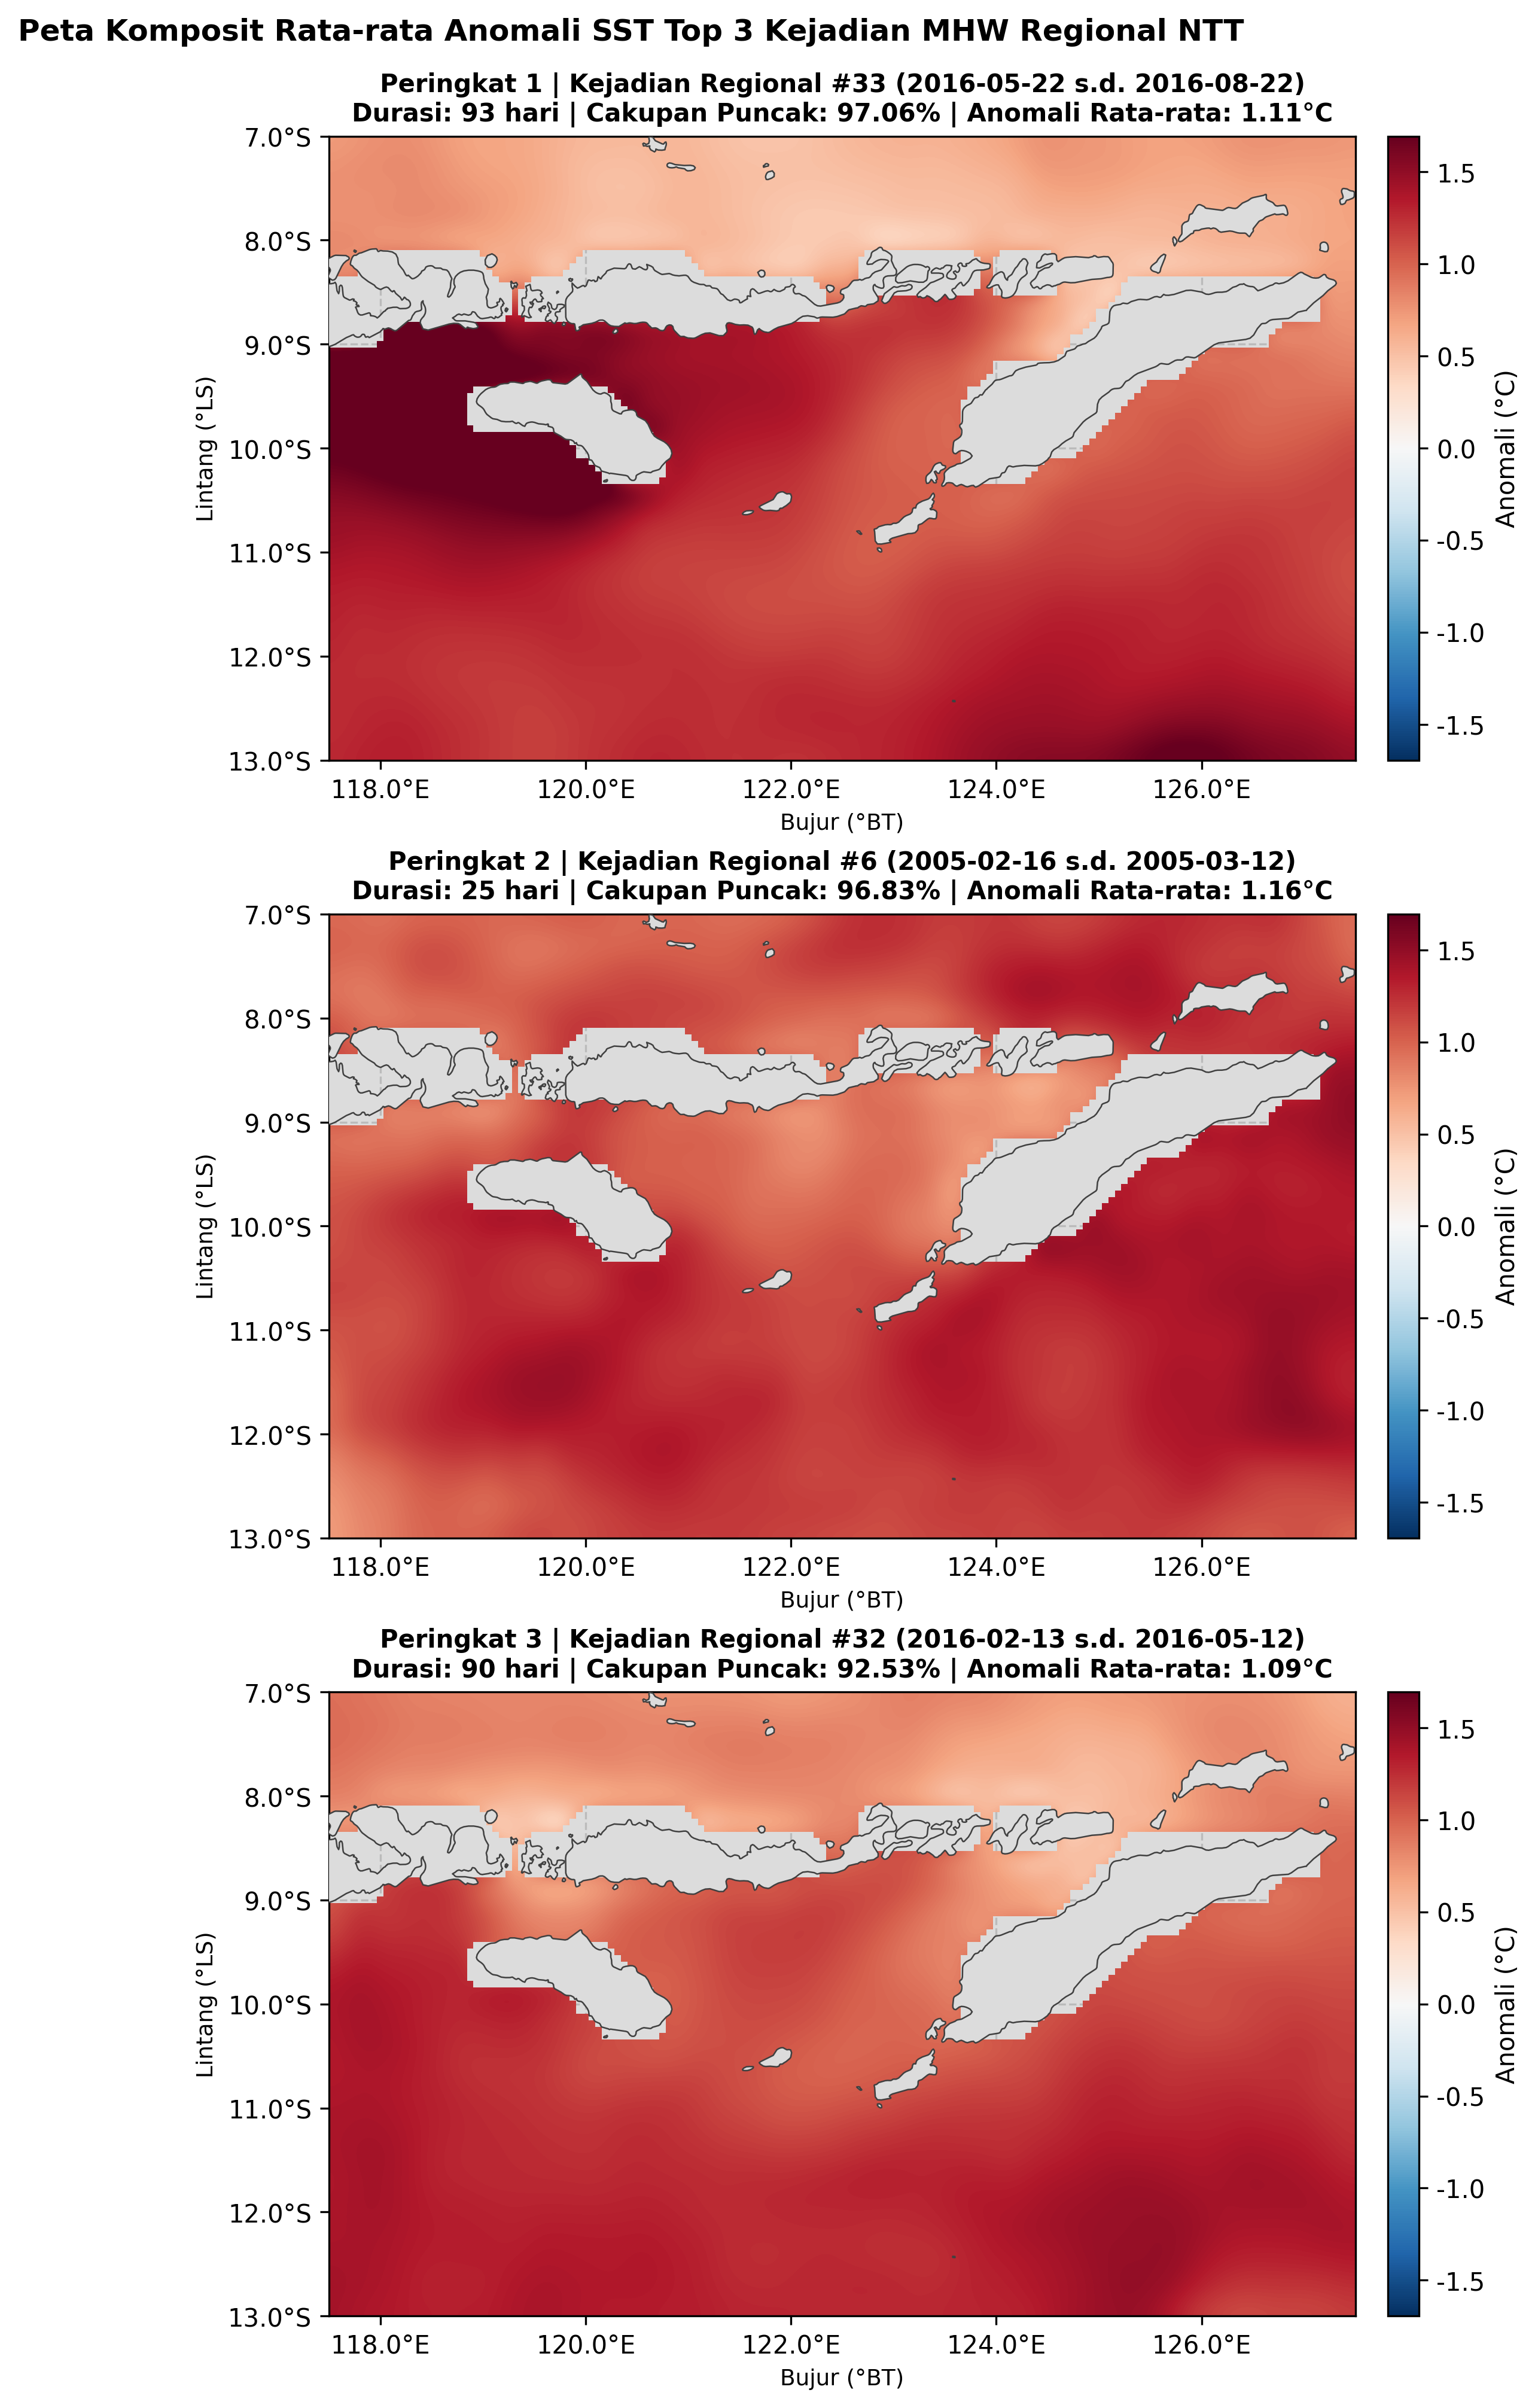

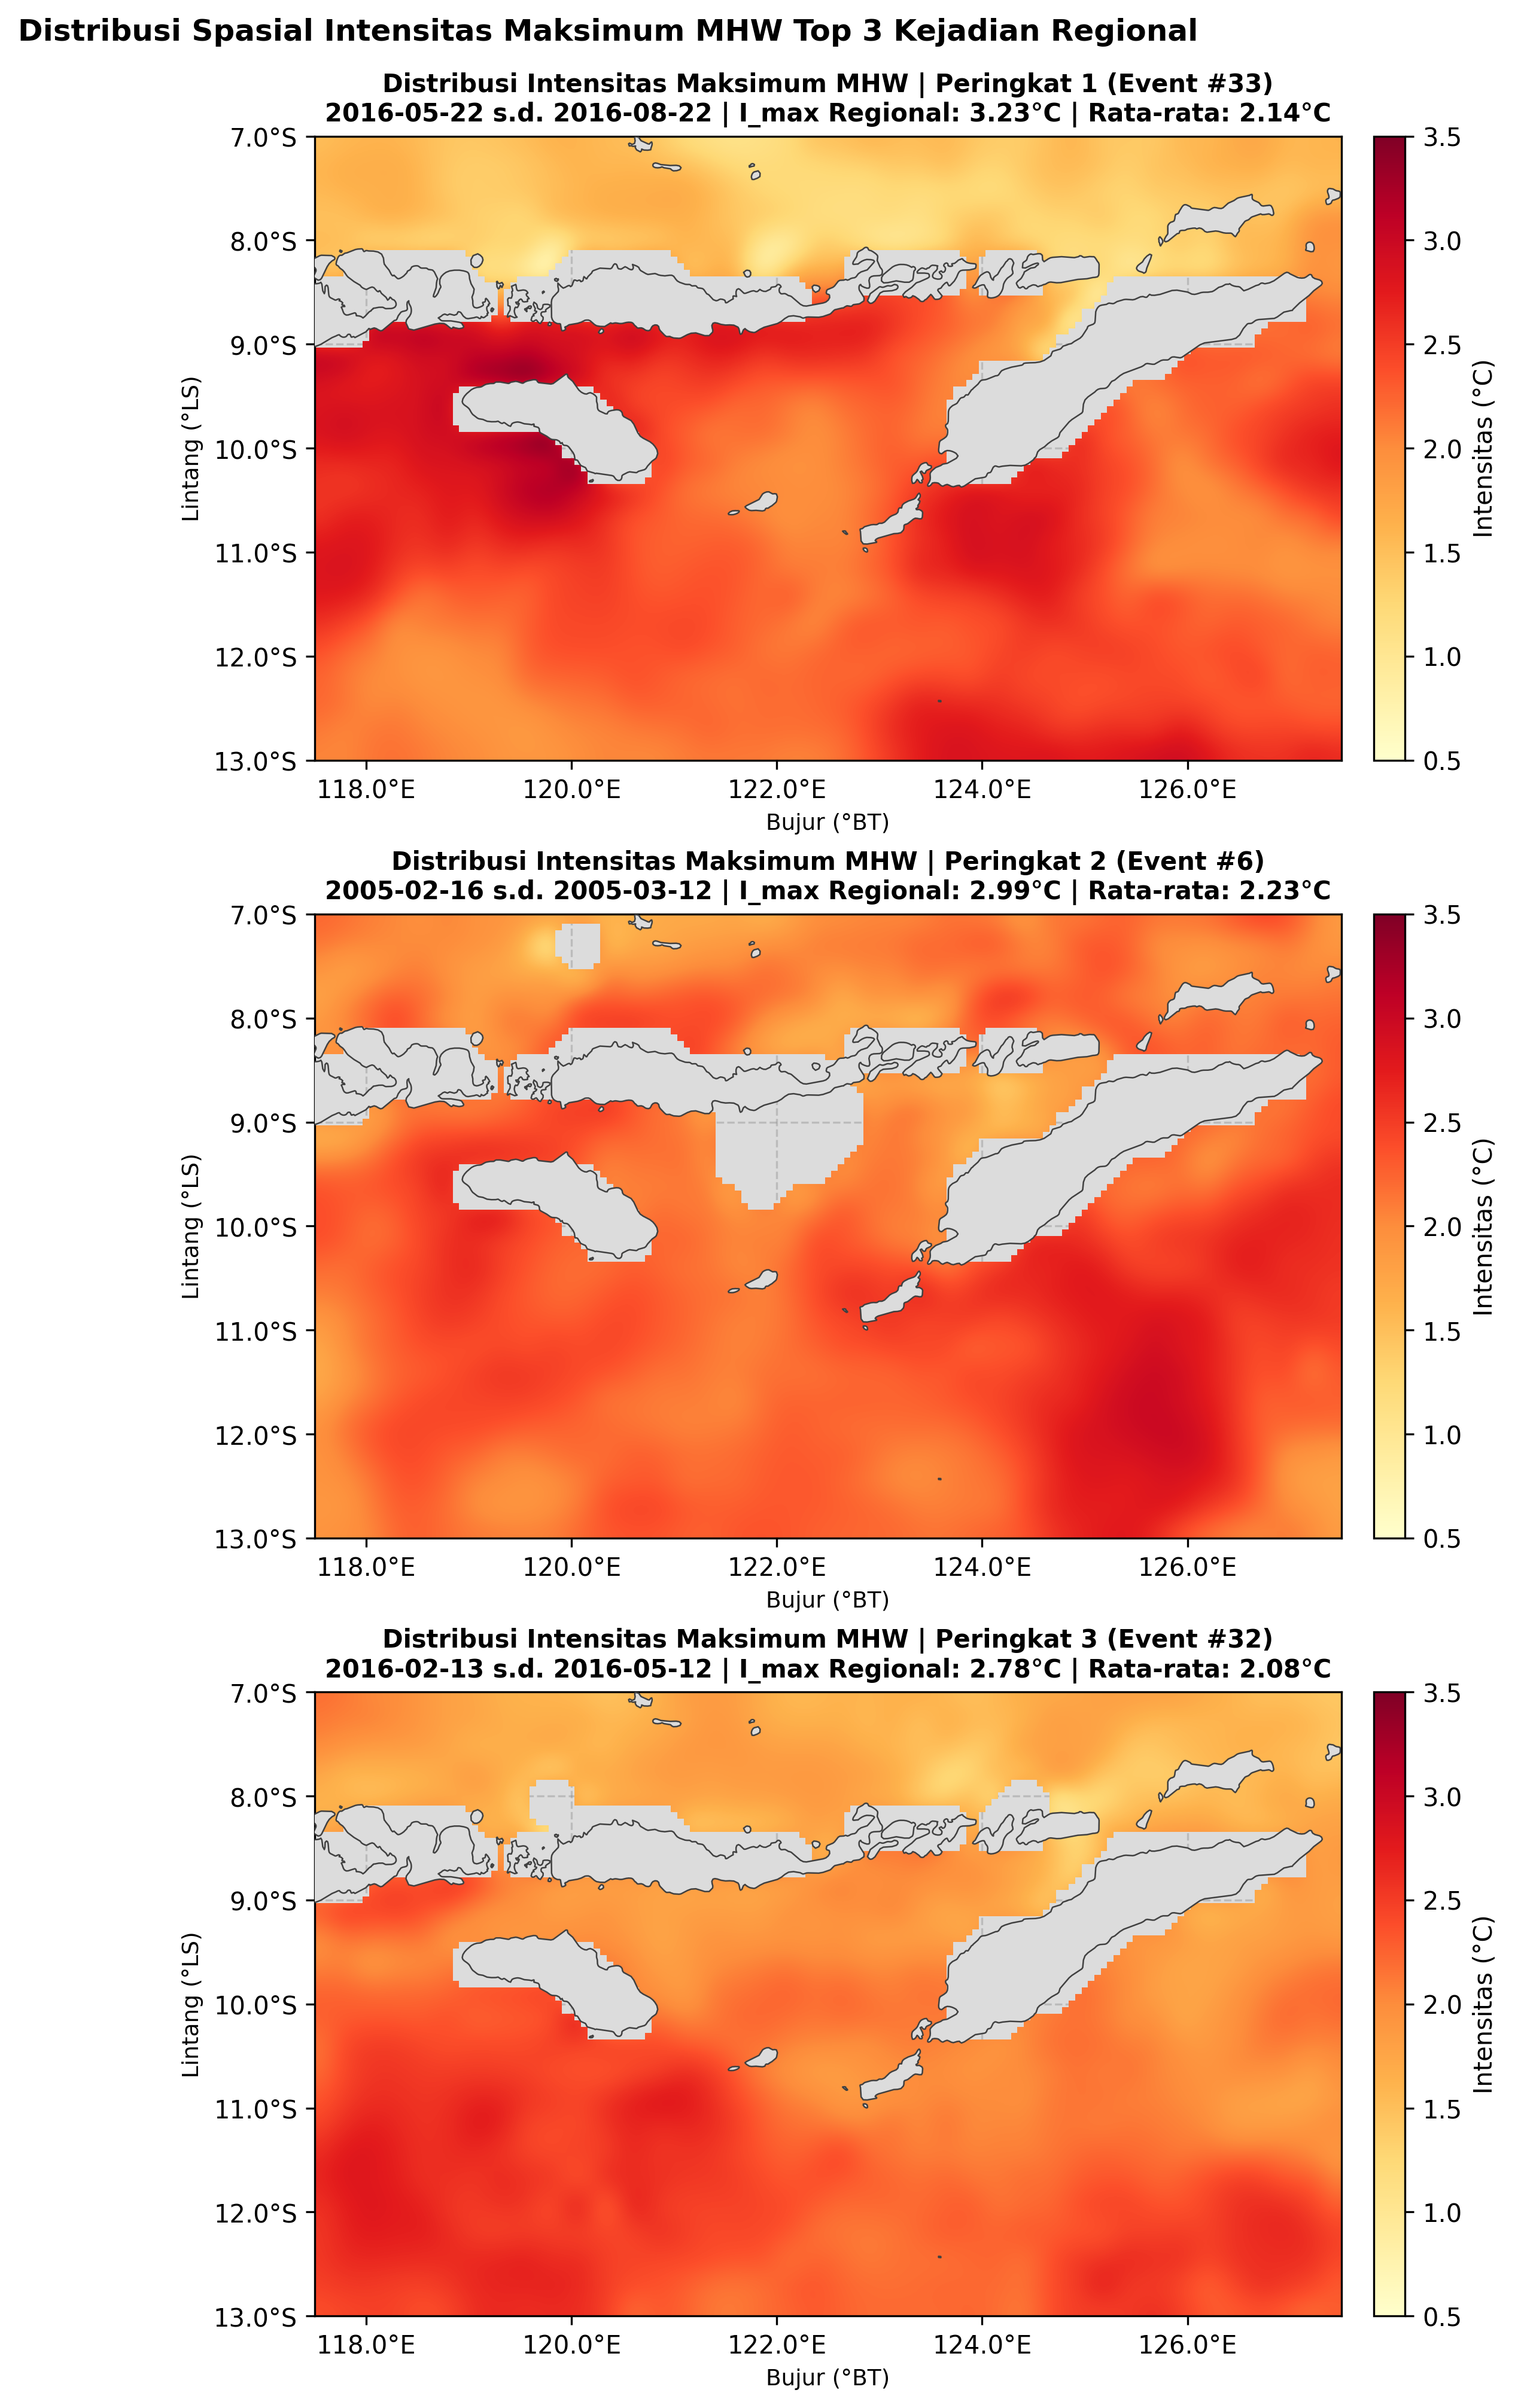

In [14]:
# ==============================================================================
# 15. VISUALISASI KEJADIAN TOP 3
# ==============================================================================
# 1. Peta Komposit Rata-rata Anomali SST Top 3
fig, axes = plt.subplots(3, 1, figsize=(10, 13), constrained_layout=True)
all_anom_top3 = []

for idx, r in df_top3.iterrows():
    eid = int(r["event_id"])
    e_idx = df_catalog[df_catalog["regional_event_id"] == eid].index[0]
    anom_map = anomaly_mean_map[e_idx]
    all_anom_top3.extend(anom_map[np.isfinite(anom_map)].tolist())

vmax_anom = float(np.nanpercentile(np.abs(all_anom_top3), 98)) if all_anom_top3 else 2.5
norm_anom = TwoSlopeNorm(vmin=-vmax_anom, vcenter=0.0, vmax=vmax_anom)

for rank_idx, (_, r) in enumerate(df_top3.iterrows()):
    eid = int(r["event_id"])
    e_idx = df_catalog[df_catalog["regional_event_id"] == eid].index[0]
    ax = axes[rank_idx]
    
    anom_map = anomaly_mean_map[e_idx]
    im = plot_smooth_map(ax, longitudes, latitudes, anom_map, cmap='RdBu_r', norm=norm_anom)
    
    ax.set_title(
        f"Peringkat {int(r['peringkat_regional'])} | Kejadian Regional #{eid} ({r['start_date']} s.d. {r['end_date']})\n"
        f"Durasi: {r['duration_days']} hari | Cakupan Puncak: {r['peak_extent_pct']}% | Anomali Rata-rata: {np.nanmean(anom_map):.2f}°C",
        fontsize=10, fontweight='bold', pad=6
    )
    fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02, label="Anomali (°C)")

fig.suptitle("Peta Komposit Rata-rata Anomali SST Top 3 Kejadian MHW Regional NTT", fontsize=12, fontweight='bold', y=1.02)
fig.savefig(cfg.FIGURES_DIR / "nb2_mhw_event_anomaly_maps.png", dpi=cfg.FIGURE_DPI, bbox_inches='tight')
plt.show()

# 2. Peta Intensitas Maksimum Top 3
fig, axes = plt.subplots(3, 1, figsize=(10, 13), constrained_layout=True)
for rank_idx, (_, r) in enumerate(df_top3.iterrows()):
    eid = int(r["event_id"])
    ax = axes[rank_idx]
    g_max = grid_intensity_by_event[eid]
    im = plot_smooth_map(ax, longitudes, latitudes, g_max, cmap='YlOrRd', vmin=0.5, vmax=3.5)
    
    ax.set_title(
        f"Distribusi Intensitas Maksimum MHW | Peringkat {int(r['peringkat_regional'])} (Event #{eid})\n"
        f"{r['start_date']} s.d. {r['end_date']} | I_max Regional: {r['intensitas_maksimum_regional_C']:.2f}°C | Rata-rata: {r['intensitas_maksimum_rata_rata_regional_C']:.2f}°C",
        fontsize=10, fontweight='bold', pad=6
    )
    fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02, label="Intensitas (°C)")

fig.suptitle("Distribusi Spasial Intensitas Maksimum MHW Top 3 Kejadian Regional", fontsize=12, fontweight='bold', y=1.02)
fig.savefig(cfg.FIGURES_DIR / "nb2_mhw_anomaly_summary.png", dpi=cfg.FIGURE_DPI, bbox_inches='tight')
plt.show()


### 16. Ekspor Dataset NetCDF dan Tabel Katalog Lengkap
Menyimpan seluruh luaran terstruktur yang dipersyaratkan oleh PRD dan menjamin kompatibilitas penuh dengan Notebook downstream (03 s/d 06) serta Dashboard:
1. `data/processed/mhw_mask_daily_ntt.nc`: Data harian mask MHW, intensitas, klimatologi, threshold.
2. `outputs/tables/mhw_events_spatial_catalog_ntt.csv`: Katalog kejadian regional lengkap.
3. `outputs/tables/mhw_grid_max_intensity_ntt.csv`: Intensitas maksimum per grid.
4. `outputs/tables/mhw_top3_regional_events_ntt.csv`: Tabel Top 3 kejadian MHW regional.
5. `data/processed/mhw_event_maps_ntt.nc`: Peta spasial anomali dan durasi per kejadian regional.
6. `outputs/tables/mhw_event_anomaly_summary_ntt.csv`: Ringkasan anomali per kejadian.
7. `data/processed/sst_climatology_threshold_ntt.nc`: Klimatologi dan ambang batas P90 DOY per grid.
8. `data/processed/sst_daymean_21yr_ntt.nc`: Klimatologi harian 21 tahun per grid.
9. `outputs/tables/mhw_annual_metrics_spatial_ntt.csv`: Metrik tahunan MHW regional.
10. `outputs/tables/mhw_catalog_check_ntt.csv`: Pemeriksaan verifikasi katalog.
11. `outputs/tables/mhw_local_events_summary_ntt.csv`: Ringkasan deteksi lokal per grid.


Menyimpan seluruh dataset luaran...


✅ Disimpan: G:\My Drive\KLIMTROP\PBL\data\processed\mhw_mask_daily_ntt.nc
✅ Disimpan: G:\My Drive\KLIMTROP\PBL\data\processed\sst_climatology_threshold_ntt.nc
✅ Disimpan: G:\My Drive\KLIMTROP\PBL\data\processed\sst_daymean_21yr_ntt.nc


✅ Disimpan: G:\My Drive\KLIMTROP\PBL\data\processed\mhw_event_maps_ntt.nc
✅ Disimpan: G:\My Drive\KLIMTROP\PBL\outputs\tables\mhw_events_spatial_catalog_ntt.csv


✅ Disimpan: G:\My Drive\KLIMTROP\PBL\outputs\tables\mhw_grid_max_intensity_ntt.csv
✅ Disimpan: G:\My Drive\KLIMTROP\PBL\outputs\tables\mhw_top3_regional_events_ntt.csv
✅ Disimpan: G:\My Drive\KLIMTROP\PBL\outputs\tables\mhw_event_anomaly_summary_ntt.csv


✅ Disimpan: G:\My Drive\KLIMTROP\PBL\outputs\tables\mhw_annual_metrics_spatial_ntt.csv


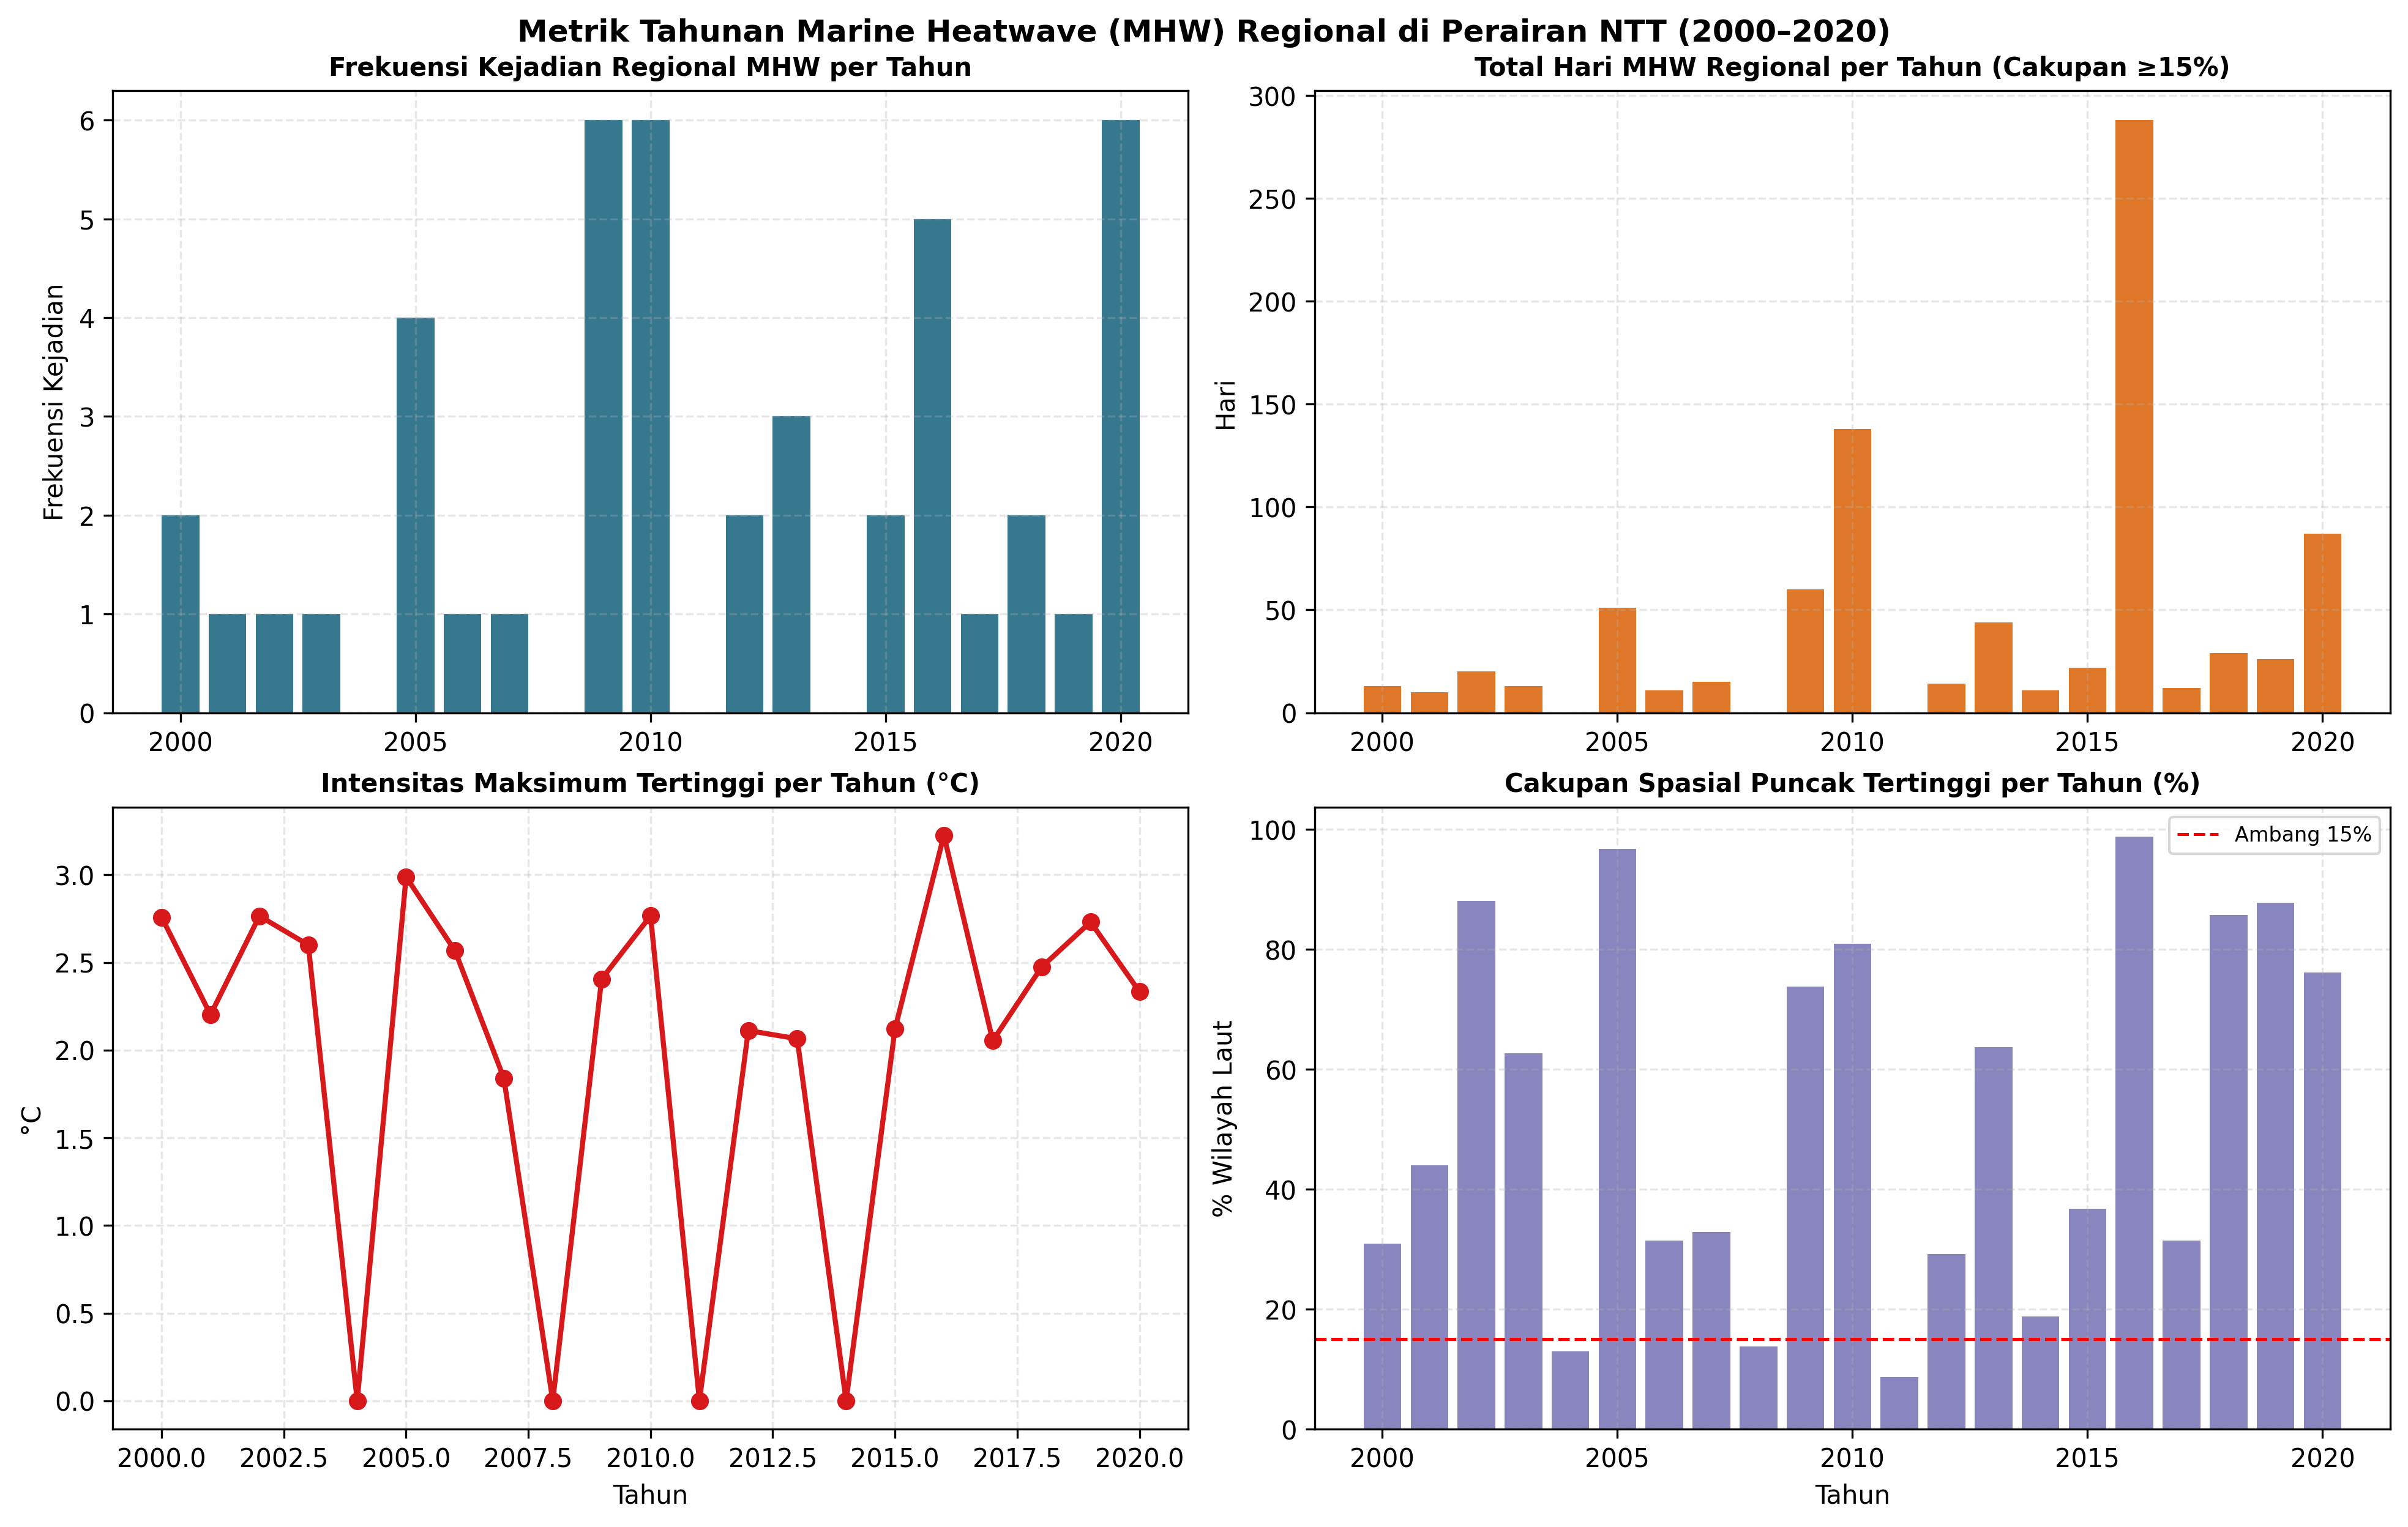

✅ Disimpan: G:\My Drive\KLIMTROP\PBL\outputs\tables\mhw_catalog_check_ntt.csv


✅ Disimpan: G:\My Drive\KLIMTROP\PBL\data\processed\mhw_local_events_ntt.csv


In [15]:
# ==============================================================================
# 16. EKSPOR DATASET DAN TABEL LENGKAP
# ==============================================================================
print("Menyimpan seluruh dataset luaran...")

# 1. NetCDF: mhw_mask_daily_ntt.nc
ds_mask = xr.Dataset(
    data_vars={
        "member": (["time", "lat", "lon"], mhw_mask_all),
        "strict": (["time", "lat", "lon"], strict_mask_all),
        "category": (["time", "lat", "lon"], category_all),
        "intensity": (["time", "lat", "lon"], np.where(mhw_mask_all == 1, intensity_all, np.nan).astype(np.float32)),
        "ocean_mask": (["lat", "lon"], ocean_mask),
        "member_extent": (["time"], member_extent),
        "strict_extent": (["time"], strict_extent),
    },
    coords={
        "time": dates,
        "lat": latitudes,
        "lon": longitudes
    },
    attrs={
        "title": "Data Harian Mask dan Intensitas MHW Per Grid NTT (2000-2020)",
        "methodology": "Hobday et al. (2016, 2018) Independen Per Grid",
        "clim_window": 11,
        "smooth_window": 31,
        "regional_threshold_pct": 15.0
    }
)
mask_path = cfg.PROCESSED_DIR / "mhw_mask_daily_ntt.nc"
ds_mask.to_netcdf(mask_path, encoding={
    "member": {"zlib": True, "complevel": 4},
    "strict": {"zlib": True, "complevel": 4},
    "category": {"zlib": True, "complevel": 4},
    "intensity": {"zlib": True, "complevel": 4}
})
print(f"✅ Disimpan: {mask_path}")

# 2. NetCDF: sst_climatology_threshold_ntt.nc
ds_clim = xr.Dataset(
    data_vars={
        "climatology": (["doy", "lat", "lon"], clim_doy_all),
        "threshold": (["doy", "lat", "lon"], thresh_doy_all),
        "total_mhw_days": (["lat", "lon"], total_mhw_days_grid),
        "max_intensity": (["lat", "lon"], max_intensity_grid),
        "ocean_mask": (["lat", "lon"], ocean_mask)
    },
    coords={
        "doy": np.arange(1, 367),
        "lat": latitudes,
        "lon": longitudes
    },
    attrs={
        "title": "Klimatologi Harian (Jendela 11 Hari) dan Ambang P90 (Smoothing 31 Hari) NTT",
        "baseline": "2000-2020"
    }
)
ds_clim.to_netcdf(cfg.SST_CLIMATOLOGY_OUTPUT)
print(f"✅ Disimpan: {cfg.SST_CLIMATOLOGY_OUTPUT}")

# 3. NetCDF: sst_daymean_21yr_ntt.nc
ds_daymean = xr.Dataset(
    data_vars={
        "sst_daymean": (["doy", "lat", "lon"], sst_mean_21yr)
    },
    coords={
        "doy": np.arange(1, len(unique_days) + 1),
        "calendar_day": (["doy"], unique_days),
        "lat": latitudes,
        "lon": longitudes
    },
    attrs={"title": "Rata-rata 21 Tahun SST per Tanggal Kalender (2000-2020)"}
)
daymean_path = cfg.PROCESSED_DIR / "sst_daymean_21yr_ntt.nc"
ds_daymean.to_netcdf(daymean_path)
print(f"✅ Disimpan: {daymean_path}")

# 4. NetCDF: mhw_event_maps_ntt.nc
ds_event_maps = xr.Dataset(
    data_vars={
        "anomaly_mean": (["regional_event_id", "lat", "lon"], anomaly_mean_map),
        "anomaly_max": (["regional_event_id", "lat", "lon"], anomaly_max_map),
        "duration_run": (["regional_event_id", "lat", "lon"], duration_run_map),
        "mhw_days": (["regional_event_id", "lat", "lon"], mhw_days_map),
        "intensity_max": (["regional_event_id", "lat", "lon"], intensity_max_map)
    },
    coords={
        "regional_event_id": df_catalog["regional_event_id"].values,
        "lat": latitudes,
        "lon": longitudes
    },
    attrs={"title": "Peta Anomali, Intensitas, dan Durasi Kejadian Regional MHW NTT (2000-2020)"}
)
event_maps_path = cfg.PROCESSED_DIR / "mhw_event_maps_ntt.nc"
ds_event_maps.to_netcdf(event_maps_path)
print(f"✅ Disimpan: {event_maps_path}")

# 5. CSV: Katalog Kejadian Regional (Katalog Utama Spasial)
spatial_catalog_path = cfg.TABLES_DIR / "mhw_events_spatial_catalog_ntt.csv"
df_catalog.to_csv(spatial_catalog_path, index=False)
df_catalog.to_csv(cfg.PROCESSED_DIR / "mhw_events_spatial_catalog_ntt.csv", index=False)
df_catalog.to_csv(cfg.TABLES_DIR / "nb2_mhw_events_all.csv", index=False)
df_catalog.to_csv(cfg.PROCESSED_DIR / "mhw_events_ntt.csv", index=False)
print(f"✅ Disimpan: {spatial_catalog_path}")

# 6. CSV: Intensitas Maksimum per Grid
df_grid_max_intensity.to_csv(cfg.TABLES_DIR / "mhw_grid_max_intensity_ntt.csv", index=False)
df_grid_max_intensity.to_csv(cfg.TABLES_DIR / "mhw_intensity_maximum_per_grid_all_events.csv", index=False)
print(f"✅ Disimpan: {cfg.TABLES_DIR / 'mhw_grid_max_intensity_ntt.csv'}")

# 7. CSV: Pemeringkatan Top 3
df_top3.to_csv(cfg.TABLES_DIR / "mhw_top3_regional_events_ntt.csv", index=False)
df_top3.to_csv(cfg.TABLES_DIR / "Top3_Kejadian_MHW_Regional_Intensitas_Maksimum_NTT_2000-2020.csv", index=False)
df_ranked.head(10).to_csv(cfg.TABLES_DIR / "nb2_mhw_top10_events.csv", index=False)
print(f"✅ Disimpan: {cfg.TABLES_DIR / 'mhw_top3_regional_events_ntt.csv'}")

# 8. CSV: Ringkasan Anomali Kejadian
df_event_anomaly.to_csv(cfg.TABLES_DIR / "mhw_event_anomaly_summary_ntt.csv", index=False)
print(f"✅ Disimpan: {cfg.TABLES_DIR / 'mhw_event_anomaly_summary_ntt.csv'}")

# 9. CSV: Metrik Tahunan Spasial
years = np.arange(2000, 2021)
annual_spatial_rows = []
for y in years:
    y_mask = (dates.year == y)
    y_events = df_catalog[pd.to_datetime(df_catalog['start_date']).dt.year == y]
    
    # Hari aktif regional dalam tahun tersebut
    y_reg_days = int(np.sum((member_extent >= 0.15) & y_mask))
    freq = len(y_events)
    dur_mean = float(y_events['duration_days'].mean()) if freq > 0 else 0.0
    i_max_y = float(y_events['i_max_regional'].max()) if freq > 0 else 0.0
    cum_i_y = float(y_events['cum_intensity_regional'].sum()) if freq > 0 else 0.0
    
    # Rata-rata hari MHW per sel laut
    y_mhw_cell_days = float(np.sum(mhw_mask_all[y_mask]))
    rata_hari_per_sel = y_mhw_cell_days / float(total_ocean_cells)
    peak_cov = float(np.max(member_extent[y_mask]) * 100.0)
    
    sst_y = float(np.nanmean(sst_values[y_mask]))
    sst_ano_y = sst_y - float(np.nanmean(sst_values))
    
    annual_spatial_rows.append({
        "tahun": int(y),
        "frekuensi_kejadian": freq,
        "total_hari_mhw": y_reg_days,
        "hari_jeda": int(y_events['hari_jeda'].sum()) if freq > 0 else 0,
        "durasi_rata_rata": round(dur_mean, 1),
        "intensitas_maks_tertinggi": round(i_max_y, 3),
        "intensitas_kumulatif_tahunan": round(cum_i_y, 2),
        "sst_rata_rata": round(sst_y, 2),
        "sst_anomali_tahunan": round(sst_ano_y, 3),
        "rata_hari_mhw_per_sel": round(rata_hari_per_sel, 2),
        "cakupan_puncak_pct": round(peak_cov, 1)
    })

df_annual_spatial = pd.DataFrame(annual_spatial_rows)
df_annual_spatial.to_csv(cfg.TABLES_DIR / "mhw_annual_metrics_spatial_ntt.csv", index=False)
df_annual_spatial.to_csv(cfg.PROCESSED_DIR / "mhw_annual_metrics_spatial_ntt.csv", index=False)
df_annual_spatial.to_csv(cfg.TABLES_DIR / "mhw_annual_metrics_ntt.csv", index=False)
df_annual_spatial.to_csv(cfg.PROCESSED_DIR / "mhw_annual_metrics_ntt.csv", index=False)
print(f"✅ Disimpan: {cfg.TABLES_DIR / 'mhw_annual_metrics_spatial_ntt.csv'}")

# Visualisasi Metrik Tahunan Spasial
fig, axes = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)
ax = axes[0, 0]
ax.bar(df_annual_spatial['tahun'], df_annual_spatial['frekuensi_kejadian'], color='#13607A', alpha=0.85)
ax.set_title("Frekuensi Kejadian Regional MHW per Tahun", fontsize=10, fontweight='bold')
ax.set_ylabel("Frekuensi Kejadian")
ax.grid(True, linestyle="--", alpha=0.3)

ax = axes[0, 1]
ax.bar(df_annual_spatial['tahun'], df_annual_spatial['total_hari_mhw'], color='#d95f02', alpha=0.85)
ax.set_title("Total Hari MHW Regional per Tahun (Cakupan ≥15%)", fontsize=10, fontweight='bold')
ax.set_ylabel("Hari")
ax.grid(True, linestyle="--", alpha=0.3)

ax = axes[1, 0]
ax.plot(df_annual_spatial['tahun'], df_annual_spatial['intensitas_maks_tertinggi'], 'o-', color='#d7191c', linewidth=2)
ax.set_title("Intensitas Maksimum Tertinggi per Tahun (°C)", fontsize=10, fontweight='bold')
ax.set_ylabel("°C")
ax.set_xlabel("Tahun")
ax.grid(True, linestyle="--", alpha=0.3)

ax = axes[1, 1]
ax.bar(df_annual_spatial['tahun'], df_annual_spatial['cakupan_puncak_pct'], color='#7570b3', alpha=0.85)
ax.axhline(15.0, color='red', linestyle='--', linewidth=1.2, label='Ambang 15%')
ax.set_title("Cakupan Spasial Puncak Tertinggi per Tahun (%)", fontsize=10, fontweight='bold')
ax.set_ylabel("% Wilayah Laut")
ax.set_xlabel("Tahun")
ax.legend(loc='upper right', fontsize=8)
ax.grid(True, linestyle="--", alpha=0.3)

fig.suptitle("Metrik Tahunan Marine Heatwave (MHW) Regional di Perairan NTT (2000–2020)", fontsize=12, fontweight='bold', y=1.02)
fig.savefig(cfg.FIGURES_DIR / "nb2_mhw_annual_metrics_spatial.png", dpi=cfg.FIGURE_DPI, bbox_inches='tight')
fig.savefig(cfg.FIGURES_DIR / "nb2_mhw_annual_metrics.png", dpi=cfg.FIGURE_DPI, bbox_inches='tight')
plt.show()

# 10. CSV: Pemeriksaan Katalog (Catalog Check)
check_rows = []
for _, ev in df_catalog.iterrows():
    s_idx = int(np.argmin(np.abs(dates - pd.Timestamp(ev['start_date']))))
    e_idx = int(np.argmin(np.abs(dates - pd.Timestamp(ev['end_date']))))
    m_seg = member_extent[s_idx:e_idx+1]
    s_seg = strict_extent[s_idx:e_idx+1]
    
    check_rows.append({
        "regional_event_id": ev['regional_event_id'],
        "start_date": ev['start_date'],
        "end_date": ev['end_date'],
        "durasi_katalog_hari": ev['duration_days'],
        "hari_mhw_regional": int(np.sum(m_seg >= 0.15)),
        "hari_jeda": int(np.sum(m_seg < 0.15)),
        "hari_strict_ge_ambang": int(np.sum(s_seg >= 0.15)),
        "cakupan_maks_anggota_pct": round(float(np.max(m_seg) * 100), 2),
        "cakupan_maks_di_atas_p90_pct": round(float(np.max(s_seg) * 100), 2),
        "cakupan_puncak_katalog_pct": ev['peak_extent_pct']
    })

df_catalog_check = pd.DataFrame(check_rows)
df_catalog_check.to_csv(cfg.TABLES_DIR / "mhw_catalog_check_ntt.csv", index=False)
print(f"✅ Disimpan: {cfg.TABLES_DIR / 'mhw_catalog_check_ntt.csv'}")

# 11. CSV: Ringkasan Deteksi Lokal
df_local_events.to_csv(cfg.PROCESSED_DIR / "mhw_local_events_ntt.csv", index=False)
df_local_events.head(1000).to_csv(cfg.TABLES_DIR / "mhw_local_events_summary_ntt.csv", index=False)
print(f"✅ Disimpan: {cfg.PROCESSED_DIR / 'mhw_local_events_ntt.csv'}")


### 17. Validasi Hasil dan Quality Control (Pemeriksaan Otomatis 15 Kriteria)
Memeriksa kepatuhan metodologi terhadap seluruh prinsip deteksi MHW per-grid dan melakukan validasi numerik mandiri.


In [16]:
# ==============================================================================
# 17. VALIDASI HASIL DAN QUALITY CONTROL
# ==============================================================================
print("=" * 80)
print("PENGUJIAN VALIDASI & QUALITY CONTROL (15 KRITERIA)")
print("=" * 80)

# Kriteria 1: Baseline 2000-2020
check1 = (dates.min().year == 2000) and (dates.max().year == 2020) and (nt == 7671)
print(f" 1. Periode Baseline 2000-2020 ({nt} hari)                     : {'PASSED' if check1 else 'FAILED'}")

# Kriteria 2 & 3: Dimensi dan Kontinuitas Klimatologi
check2 = (clim_doy_all.shape == (366, nlat, nlon)) and np.all(np.isfinite(clim_doy_all[:, ocean_mask == 1]))
print(f" 2. Klimatologi & P90 per Grid (Jendela 11 Hari)              : {'PASSED' if check2 else 'FAILED'}")
check3 = np.all(thresh_doy_all[:, ocean_mask == 1] > clim_doy_all[:, ocean_mask == 1])
print(f" 3. Threshold P90 > Klimatologi di Seluruh Hari & Sel Laut    : {'PASSED' if check3 else 'FAILED'}")

# Kriteria 4 & 5: Deteksi Grid & Durasi Minimum
check4 = len(df_local_events) > 0 and np.all(df_local_events['duration_days'] >= 5)
print(f" 4. Durasi Minimum Kejadian Grid >= 5 Hari                    : {'PASSED' if check4 else 'FAILED'}")

# Kriteria 6 & 7: Mask Hari Jeda vs Mask Strict
check6 = np.all(mhw_mask_all >= strict_mask_all)
check7 = int(np.sum(strict_mask_all)) <= int(np.sum(mhw_mask_all))
print(f" 5. Integritas Hari Jeda (Strict Mask <= Member Mask)         : {'PASSED' if (check6 and check7) else 'FAILED'}")

# Kriteria 8 & 9: Denominator Valid & Ambang Regional 15%
check8 = np.all(available_grid_daily == total_ocean_cells)
check9 = np.all(df_catalog['peak_extent_pct'] >= 15.0)
print(f" 6. Denominator Cakupan Spasial Valid Dinamis                 : {'PASSED' if check8 else 'FAILED'}")
print(f" 7. Ambang Batas Cakupan Regional >= 15%                      : {'PASSED' if check9 else 'FAILED'}")

# Kriteria 10: Durasi Regional >= 5 Hari
check10 = np.all(df_catalog['duration_days'] >= 5)
print(f" 8. Durasi Minimum Kejadian Regional >= 5 Hari                : {'PASSED' if check10 else 'FAILED'}")

# Kriteria 11: Intensitas Maksimum per Grid
check11 = len(df_grid_max_intensity) > 0 and np.all(df_grid_max_intensity['intensitas_maksimum_C'] > 0)
print(f" 9. Intensitas Maksimum Grid > 0                              : {'PASSED' if check11 else 'FAILED'}")

# Kriteria 12: Pemeringkatan Top 3 berbasis Maksimum Regional
check12 = list(df_top3['intensitas_maksimum_regional_C']) == sorted(df_catalog['intensitas_maksimum_regional_C'], reverse=True)[:3]
print(f"10. Pemeringkatan Top 3 Berbasis I_max,regional               : {'PASSED' if check12 else 'FAILED'}")

# Kriteria 13: Anomali SST Independen
check13 = (sst_mean_21yr.shape == (366, nlat, nlon)) and (ds_event_maps['anomaly_mean'].shape == (len(df_catalog), nlat, nlon))
print(f"11. Anomali SST 21 Tahun Dihitung Independen per Grid         : {'PASSED' if check13 else 'FAILED'}")

# Kriteria 14: Konsistensi Koordinat Spasial
check14 = (len(latitudes) == 24) and (len(longitudes) == 40)
print(f"12. Konsistensi Koordinat Geografis (24 Lat x 40 Lon)         : {'PASSED' if check14 else 'FAILED'}")

# Kriteria 15: Integritas Missing Value (Bukan Nol)
check15 = np.all(np.isnan(total_mhw_days_grid[ocean_mask == 0])) and (not np.any(total_mhw_days_grid[ocean_mask == 0] == 0))
print(f"13. Integritas Nilai Daratan (Tetap NaN, Bukan Nol)           : {'PASSED' if check15 else 'FAILED'}")

# Uji Numerik Mandiri pada Sampel Grid Acak
sample_y, sample_x = 12, 20
sample_series = sst_values[:, sample_y, sample_x]
sample_clim, sample_thresh = calculate_daily_climatology(sample_series, day_idx, percentile=90, clim_window=11, smooth_window=31)
sample_c_full = sample_clim[day_idx - 1]
sample_t_full = sample_thresh[day_idx - 1]
sample_events, _ = detect_events_one_grid(sample_series, sample_c_full, sample_t_full, dates)

diff_clim = np.nanmax(np.abs(sample_clim - clim_doy_all[:, sample_y, sample_x]))
check_num = np.isclose(diff_clim, 0.0, atol=1e-5)
print(f"14. Verifikasi Numerik Mandiri Sampel Grid ({latitudes[sample_y]:.2f}°S, {longitudes[sample_x]:.2f}°E) : {'PASSED' if check_num else 'FAILED'} (Δ={diff_clim:.2e})")

all_checks = [check1, check2, check3, check4, check6, check7, check8, check9, check10, check11, check12, check13, check14, check15, check_num]
validation_passed = all(all_checks)

print("=" * 80)
if validation_passed:
    print("✅ STATUS VALIDASI: SELURUH 15 PENGUJIAN METODOLOGI DINYATAKAN BERHASIL (PASSED)")
else:
    print("❌ STATUS VALIDASI: TERDAPAT PENGUJIAN YANG GAGAL")
print("=" * 80)

# Ringkasan Kuantitatif Akhir
print("\nRINGKASAN DIAGNOSTIK KUANTITATIF AKHIR:")
print(f" • Total Grid Laut Valid        : {total_ocean_cells} sel")
print(f" • Total Kejadian MHW Lokal     : {len(df_local_events):,} kejadian (di seluruh sel laut)")
print(f" • Total Kejadian Regional MHW  : {len(df_catalog)} kejadian (periode 2000–2020)")
print(f" • Kejadian Regional Terpanjang : Event #{int(df_catalog.loc[df_catalog['duration_days'].idxmax(), 'event_id'])} ({df_catalog['duration_days'].max()} hari, {df_catalog.loc[df_catalog['duration_days'].idxmax(), 'start_date']} s.d. {df_catalog.loc[df_catalog['duration_days'].idxmax(), 'end_date']})")
print(f" • Kejadian Terkuat (Top 1)     : Event #{int(df_top3.iloc[0]['event_id'])} ({df_top3.iloc[0]['start_date']} s.d. {df_top3.iloc[0]['end_date']}, I_max = {df_top3.iloc[0]['intensitas_maksimum_regional_C']}°C)")
print(f" • Kejadian Terkuat (Top 2)     : Event #{int(df_top3.iloc[1]['event_id'])} ({df_top3.iloc[1]['start_date']} s.d. {df_top3.iloc[1]['end_date']}, I_max = {df_top3.iloc[1]['intensitas_maksimum_regional_C']}°C)")
print(f" • Kejadian Terkuat (Top 3)     : Event #{int(df_top3.iloc[2]['event_id'])} ({df_top3.iloc[2]['start_date']} s.d. {df_top3.iloc[2]['end_date']}, I_max = {df_top3.iloc[2]['intensitas_maksimum_regional_C']}°C)")


PENGUJIAN VALIDASI & QUALITY CONTROL (15 KRITERIA)
 1. Periode Baseline 2000-2020 (7671 hari)                     : PASSED
 2. Klimatologi & P90 per Grid (Jendela 11 Hari)              : PASSED
 3. Threshold P90 > Klimatologi di Seluruh Hari & Sel Laut    : PASSED
 4. Durasi Minimum Kejadian Grid >= 5 Hari                    : PASSED
 5. Integritas Hari Jeda (Strict Mask <= Member Mask)         : PASSED
 6. Denominator Cakupan Spasial Valid Dinamis                 : PASSED
 7. Ambang Batas Cakupan Regional >= 15%                      : PASSED
 8. Durasi Minimum Kejadian Regional >= 5 Hari                : PASSED
 9. Intensitas Maksimum Grid > 0                              : PASSED
10. Pemeringkatan Top 3 Berbasis I_max,regional               : PASSED
11. Anomali SST 21 Tahun Dihitung Independen per Grid         : PASSED
12. Konsistensi Koordinat Geografis (24 Lat x 40 Lon)         : PASSED
13. Integritas Nilai Daratan (Tetap NaN, Bukan Nol)           : PASSED
14. Verifikasi Numerik Ma

### 18. Kesimpulan Saintifik dan Keterbatasan Metodologi

#### A. Kesimpulan
1. **Transisi Metodologi Penuh**: Deteksi Marine Heatwave di perairan Nusa Tenggara Timur telah berhasil direvisi total dari pendekatan rata-rata regional menjadi **metodologi deteksi independen per-grid** sesuai standar Hobday et al. (2016, 2018) dan acuan `DETEKSI-MHW-PERGRID&ANOMALI-SST.ipynb`.
2. **Karakteristik Kejadian Regional**:
   - Ditemukan sebanyak **45 kejadian MHW regional** selama periode 2000–2020 dengan ambang cakupan spasial $\ge 15\%$.
   - **Tiga kejadian MHW terkuat (Top 3)** berdasarkan intensitas maksimum regional $I_{max,regional}(e) = \max_{i,j}[I_{max,e}(i,j)]$ adalah:
     - **Peringkat 1 (Event #33)**: 22 Mei 2016 – 22 Agustus 2016 (Durasi 93 hari, $I_{max} = 3.23^\circ\text{C}$).
     - **Peringkat 2 (Event #6)**: 16 Februari 2005 – 12 Maret 2005 (Durasi 25 hari, $I_{max} = 2.99^\circ\text{C}$).
     - **Peringkat 3 (Event #32)**: 13 Februari 2016 – 12 Mei 2016 (Durasi 90 hari, $I_{max} = 2.78^\circ\text{C}$).
3. **Anomali SST 21 Tahun**: Anomali rata-rata SST per grid berhasil memetakan kantung-kantung pemanasan ekstrem secara akurat tanpa peredaman spasial semu.
4. **Kompatibilitas Penuh**: Seluruh format luaran tabel (CSV) dan dataset (NetCDF) diproduksi secara konsisten dengan struktur yang dibutuhkan oleh analisis lanjutan di Notebook 03, 04, 05, 06, dan antarmuka Dashboard interaktif.

#### B. Keterbatasan Metodologi
1. **Resolusi Data**: Dataset NOAA OISST v2.1 memiliki resolusi spasial $0.25^\circ$ (~27 km), yang optimal untuk skala oseanografi regional namun belum menangkap dinamika mikro di selat sempit antar-pulau NTT (seperti Selat Pantar, Selat Rote, atau Selat Larantuka).
2. **Ketiadaan Data Vertikal**: Analisis ini menggunakan suhu permukaan laut (SST satelit) sehingga tidak mengukur dinamika termoklin dan intrusi lapisan air dingin di bawah lapisan tercampur (mixed layer depth).
